# Bangalore Cab Fare Prediction — Exploratory Data Analysis

This notebook performs exploratory data analysis on the processed
Uber fare dataset collected from Bangalore routes.

The objectives are to:

- Understand the structure and quality of the dataset
- Analyze fare distributions
- Study route and ride-type characteristics
- Analyze temporal patterns
- Investigate relationships between fare and numerical features
- Identify missing values and potential anomalies
- Derive insights that will guide feature engineering

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [147]:
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [148]:
DATA_PATH = "../data/processed/fares/uber_fares_processed.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,timestamp,time_slot,day_of_week,pickup,dropoff,pickup_category,drop_category,road_distance_km,travel_time_minutes,ride_name,seats,eta_minutes,current_price
0,2026-08-30 16:22:06.459051+05:30,15:00,Sunday,Brand Factory,NCS Elite,mall,residential_area,23.757,50.42,Go Non AC,4.0,5.0,528.89
1,2026-08-30 16:22:06.459051+05:30,15:00,Sunday,Brand Factory,NCS Elite,mall,residential_area,23.757,50.42,Auto,3.0,2.0,533.30
2,2026-08-30 16:22:06.459051+05:30,15:00,Sunday,Brand Factory,NCS Elite,mall,residential_area,23.757,50.42,Uber Go AC,4.0,4.0,609.13
3,2026-08-30 16:22:06.459051+05:30,15:00,Sunday,Brand Factory,NCS Elite,mall,residential_area,23.757,50.42,Bike Saver,1.0,7.0,324.58
4,2026-08-30 16:22:06.459051+05:30,15:00,Sunday,Brand Factory,NCS Elite,mall,residential_area,23.757,50.42,Premier AC,4.0,4.0,793.81


## 1. Dataset Overview

We first examine the size, structure, data types, and basic characteristics
of the processed fare dataset.

In [149]:
print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])

print ("The Information: ")
print(df.info())

print("Dtypes: ")
print(df.dtypes)

print("Description: ")
print(df.describe().T)

print("Cardinality: ")

cardinality = pd.DataFrame({
    "unique_values": df.nunique(),
    "missing_values": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})
cardinality.sort_values("unique_values", ascending=False)
print(cardinality)


Number of rows    : 15323
Number of columns : 13
The Information: 
<class 'pandas.DataFrame'>
RangeIndex: 15323 entries, 0 to 15322
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            15323 non-null  str    
 1   time_slot            15323 non-null  str    
 2   day_of_week          15323 non-null  str    
 3   pickup               15323 non-null  str    
 4   dropoff              15323 non-null  str    
 5   pickup_category      15323 non-null  str    
 6   drop_category        15323 non-null  str    
 7   road_distance_km     15323 non-null  float64
 8   travel_time_minutes  15323 non-null  float64
 9   ride_name            15323 non-null  str    
 10  seats                11571 non-null  float64
 11  eta_minutes          14213 non-null  float64
 12  current_price        15323 non-null  float64
dtypes: float64(5), str(8)
memory usage: 1.5 MB
None
Dtypes: 
timestamp              

## 2. Data Quality Checks

We check for duplicate observations and missing values before performing
the detailed exploratory analysis.

In [150]:
# Duplicate Rows
print("Duplicate rows:", df.duplicated().sum())

# Null Values
print("Number of Missing Values: ",df.isnull().sum())

# Missing Value Table
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing = missing[missing["missing_count"] > 0]
missing.sort_values("missing_count", ascending=False)
print(missing)

Duplicate rows: 0
Number of Missing Values:  timestamp                 0
time_slot                 0
day_of_week               0
pickup                    0
dropoff                   0
pickup_category           0
drop_category             0
road_distance_km          0
travel_time_minutes       0
ride_name                 0
seats                  3752
eta_minutes            1110
current_price             0
dtype: int64
             missing_count  missing_percentage
seats                 3752           24.486067
eta_minutes           1110            7.244012


## 3. Target Variable Analysis

The target variable for this project is `current_price`, which represents
the observed Uber fare for a particular ride type, route, and collection time.

We analyze its central tendency, spread, distribution, skewness, and
potential extreme values before deciding how it should be handled for
machine learning.

In [151]:
print("Description of the target variable(current price): ")
print(df['current_price'].describe())



Description of the target variable(current price): 
count    15323.000000
mean       621.628904
std        447.839877
min          0.000000
25%        287.635000
50%        507.020000
75%        850.000000
max       3611.800000
Name: current_price, dtype: float64


In [152]:
print("Some more Statistical Measurements of the target variable(current price)")
print("Mean: ",df['current_price'].mean())
print("Median :", df["current_price"].median())
print("Skewness:", df["current_price"].skew())


Some more Statistical Measurements of the target variable(current price)
Mean:  621.6289042615676
Median : 507.02
Skewness: 1.4115970735519605


In [153]:
percentiles = df["current_price"].quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(percentiles)

0.01      55.7598
0.05     112.0130
0.10     161.4160
0.25     287.6350
0.50     507.0200
0.75     850.0000
0.90    1208.6500
0.95    1446.8480
0.99    2099.7800
Name: current_price, dtype: float64


Histogram


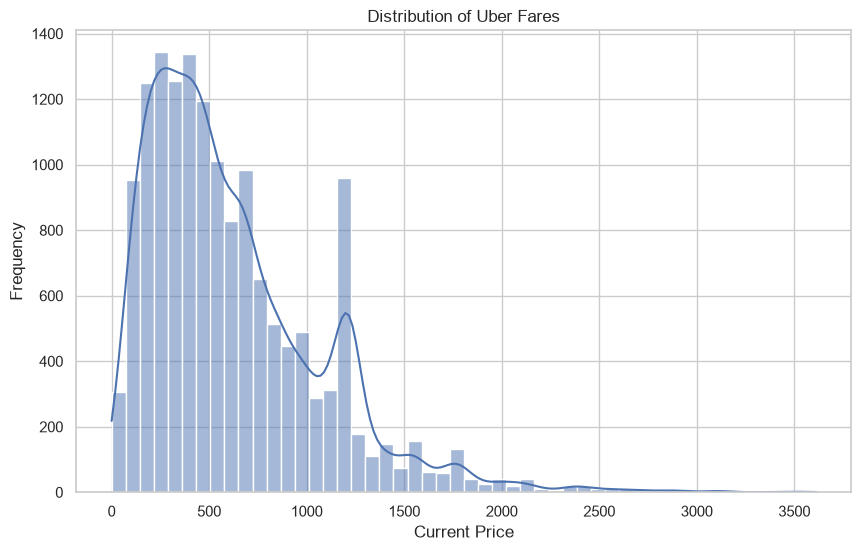

In [154]:
print("Histogram")

plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="current_price",
    bins=50,
    kde=True
)

plt.title("Distribution of Uber Fares")
plt.xlabel("Current Price")
plt.ylabel("Frequency")
plt.show()

Box Plot


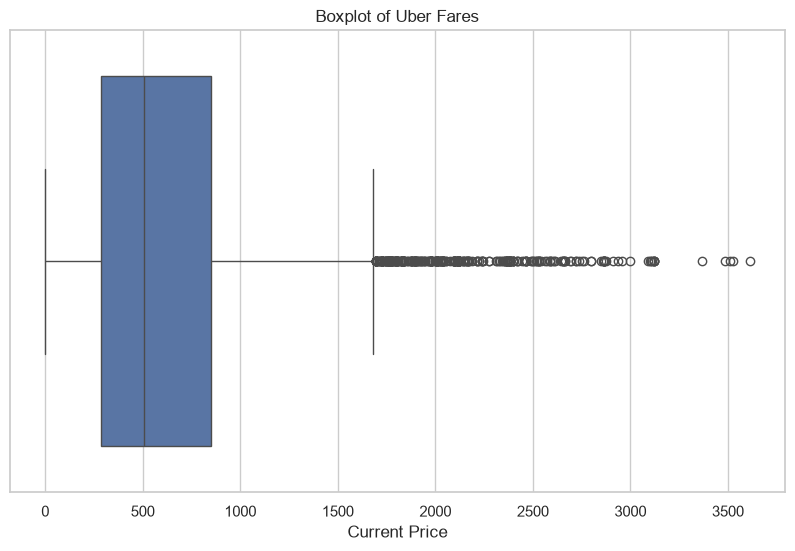

In [155]:
print("Box Plot")

plt.figure(figsize=(10,6))

sns.boxplot(
    x=df['current_price']
)

plt.title("Boxplot of Uber Fares")
plt.xlabel("Current Price")
plt.show()

### 3.1 Investigating Zero-Fare Observations

The minimum value of `current_price` is ₹0. Before deciding whether these observations are valid or represent data-collection/parsing errors, we investigate:

- How many zero-fare observations exist
- What percentage of the dataset they represent
- Which ride types contain zero fares
- Whether zero fares are concentrated in particular time slots or days
- Whether they occur for specific routes

This helps determine whether ₹0 represents a genuine fare or a data-quality issue.

In [235]:
zero_fares = df[df["current_price"] == 0]

print("Number of zero-fare observations:", len(zero_fares))
print(
    "Percentage of zero-fare observations:",
    round(len(zero_fares) / len(df) * 100, 2),
    "%"
)

Number of zero-fare observations: 1
Percentage of zero-fare observations: 0.01 %


In [236]:
print("Zero-fare observations by ride type:")
print(zero_fares["ride_name"].value_counts())

Zero-fare observations by ride type:
ride_name
Auto    1
Name: count, dtype: int64


In [237]:
print("Zero-fare observations by time slot:")
print(zero_fares["time_slot"].value_counts().sort_index())

print("\nZero-fare observations by day:")
print(zero_fares["day_of_week"].value_counts())

Zero-fare observations by time slot:
time_slot
09:00    1
Name: count, dtype: int64

Zero-fare observations by day:
day_of_week
Wednesday    1
Name: count, dtype: int64


In [238]:
zero_fares[
    [
        "timestamp",
        "time_slot",
        "day_of_week",
        "pickup",
        "dropoff",
        "ride_name",
        "seats",
        "eta_minutes",
        "current_price"
    ]
].sort_values("timestamp")

,timestamp,time_slot,day_of_week,pickup,dropoff,ride_name,seats,eta_minutes,current_price
8147,2026-09-16 09:01:26.537117+05:30,09:00,Wednesday,Bangalore Cantonment,Karnataka Pensioners Office,Auto,3.0,2.0,0.0


In [239]:
print("Zero-fare observations by route:")

zero_route_counts = (
    zero_fares
    .groupby(["pickup", "dropoff"])
    .size()
    .sort_values(ascending=False)
)

print(zero_route_counts)

Zero-fare observations by route:
pickup                dropoff                    
Bangalore Cantonment  Karnataka Pensioners Office    1
dtype: int64


In [240]:
print("Fare statistics excluding zero fares:")
print(df[df["current_price"] > 0]["current_price"].describe())

print("\nNumber of zero fares:", (df["current_price"] == 0).sum())
print("Number of positive fares:", (df["current_price"] > 0).sum())

Fare statistics excluding zero fares:
count    15322.000000
mean       621.669475
std        447.826331
min         10.980000
25%        287.670000
50%        507.035000
75%        850.000000
max       3611.800000
Name: current_price, dtype: float64

Number of zero fares: 1
Number of positive fares: 15322


### 3.2 Validating the Zero-Fare Observation Against Raw Fare Data

The zero-fare analysis identified only one ₹0 observation. Before removing it, we compare the corresponding raw fare record to determine whether the ₹0 value was genuinely returned by Uber or introduced during data collection/parsing.

In [242]:
raw_fares = pd.read_csv("../data/raw/fares/uber_fares.csv")

zero_row = zero_fares.iloc[0]

raw_candidates = raw_fares[
    (raw_fares["pickup"] == zero_row["pickup"]) &
    (raw_fares["dropoff"] == zero_row["dropoff"]) &
    (raw_fares["ride_name"] == zero_row["ride_name"]) &
    (raw_fares["time_slot"] == zero_row["time_slot"])
]

print("Number of matching raw records:", len(raw_candidates))

raw_candidates

Number of matching raw records: 1


,timestamp,time_slot,day_of_week,provider,pickup,dropoff,ride_name,seats,current_price,original_price,eta_minutes,arrival_time,promotion,description
8147,2026-09-16 09:01:26.537117+05:30,09:00,Wednesday,Uber,Bangalore Cantonment,Karnataka Pensioners Office,Auto,3.0,0.0,62.06,2.0,9:22 am,Faster,NaN


### 3.3 Conclusion: Zero-Fare Observation

Only one observation in the dataset has `current_price = ₹0`, representing approximately 0.01% of the dataset.

The corresponding raw fare record was inspected. The raw record also contains `current_price = ₹0`, confirming that the value was not introduced during processed-dataset creation. However, the same observation has an `original_price` of ₹62.06 and a `promotion` value of `Faster`, making the ₹0 current fare anomalous compared with the rest of the dataset.

Since this is an isolated observation and represents a negligible fraction of the dataset, we treat it as an anomalous target observation and remove it from the dataset used for model training.

No other zero-fare observations require investigation.

In [243]:
df = df[df["current_price"] > 0].copy()

print("Dataset shape after removing zero-fare observation:", df.shape)
print("Minimum current_price:", df["current_price"].min())

Dataset shape after removing zero-fare observation: (15322, 19)
Minimum current_price: 10.98


## 4. Numerical Feature Analysis

We examine the distributions of the numerical variables and investigate
their relationships with the target variable `current_price`.

The numerical features currently available are:

- `road_distance_km`
- `travel_time_minutes`
- `seats`
- `eta_minutes`
- `current_price`

In [156]:
print("Describing the numeric columns: ")

numeric_columns = [
    "road_distance_km",
    "travel_time_minutes",
    "seats",
    "eta_minutes",
    "current_price"
]

df[numeric_columns].describe().T

Describing the numeric columns: 


,count,mean,std,min,25%,50%,75%,max
road_distance_km,15323.0,15.512178,8.284765,2.915,9.480,14.451,20.181,69.969
travel_time_minutes,15323.0,36.112062,16.115309,8.060,22.940,34.560,47.290,99.900
seats,11571.0,3.844612,1.607368,1.000,3.000,4.000,4.000,6.000
eta_minutes,14213.0,5.222050,2.578369,1.000,3.000,5.000,7.000,19.000
current_price,15323.0,621.628904,447.839877,0.000,287.635,507.020,850.000,3611.800


In [157]:
print("The correlation of numeric columns among one another")

correlation_matrix = df[numeric_columns].corr()

correlation_matrix

The correlation of numeric columns among one another


,road_distance_km,travel_time_minutes,seats,eta_minutes,current_price
road_distance_km,1.000000,0.938160,0.022371,-0.000374,0.473918
travel_time_minutes,0.938160,1.000000,0.008799,0.009854,0.447457
seats,0.022371,0.008799,1.000000,-0.001331,0.537944
eta_minutes,-0.000374,0.009854,-0.001331,1.000000,0.160792
current_price,0.473918,0.447457,0.537944,0.160792,1.000000


Visualising the correlation matrix


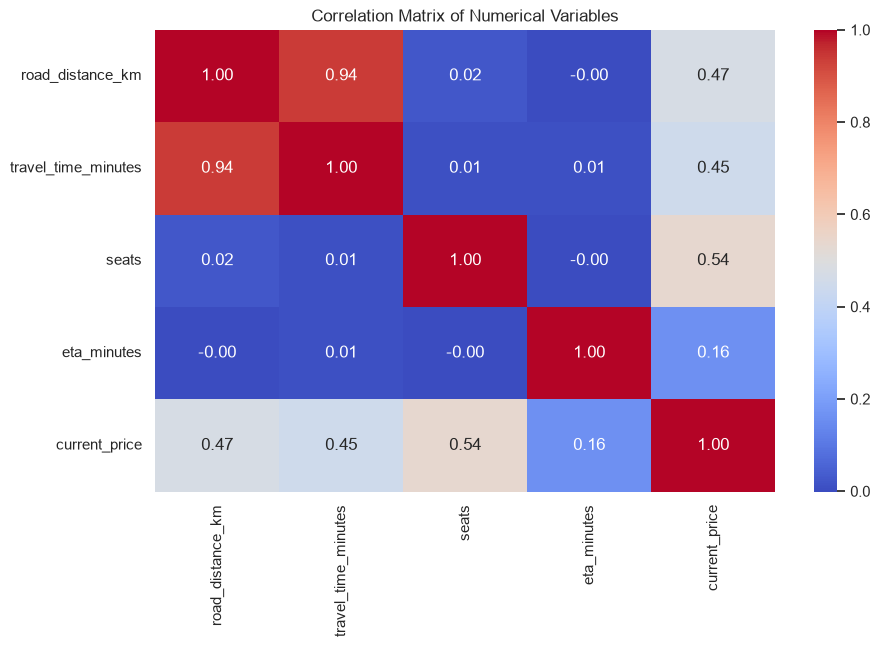

In [158]:
print("Visualising the correlation matrix")

plt.figure(figsize=(10,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

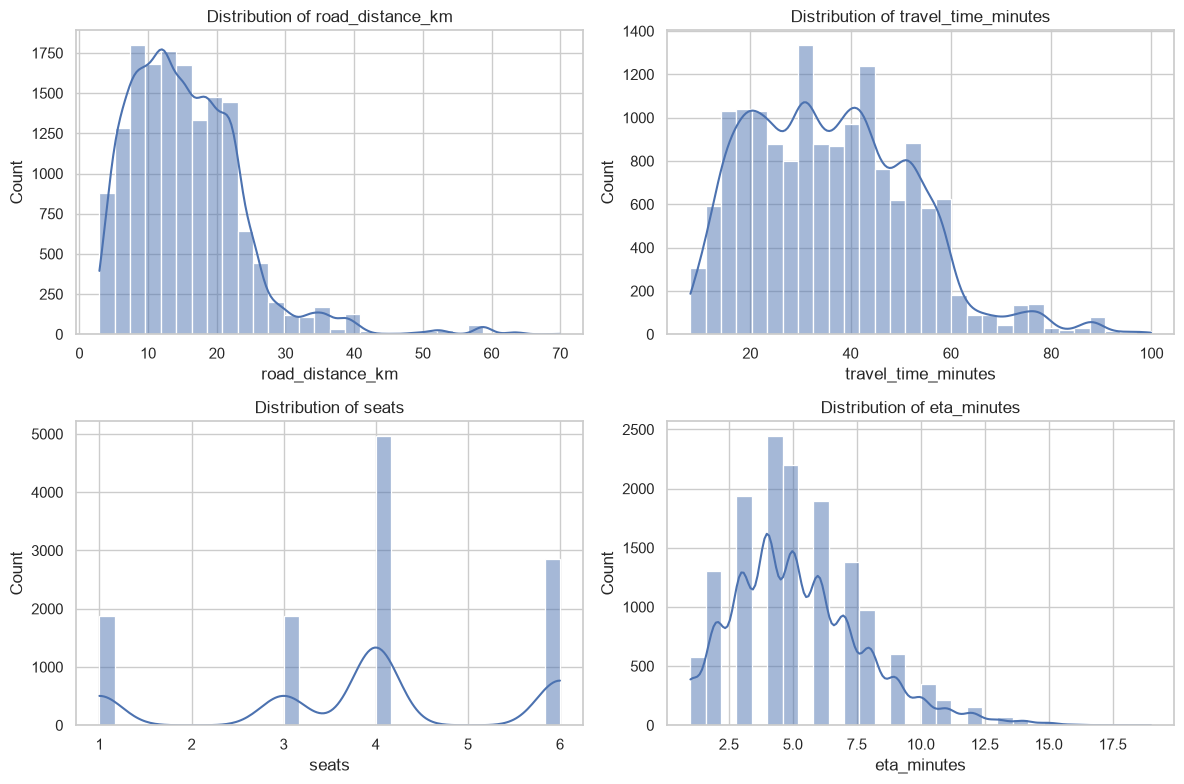

In [159]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

numerical_features = [
    "road_distance_km",
    "travel_time_minutes",
    "seats",
    "eta_minutes"
]

for ax, column in zip(axes.flat, numerical_features):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

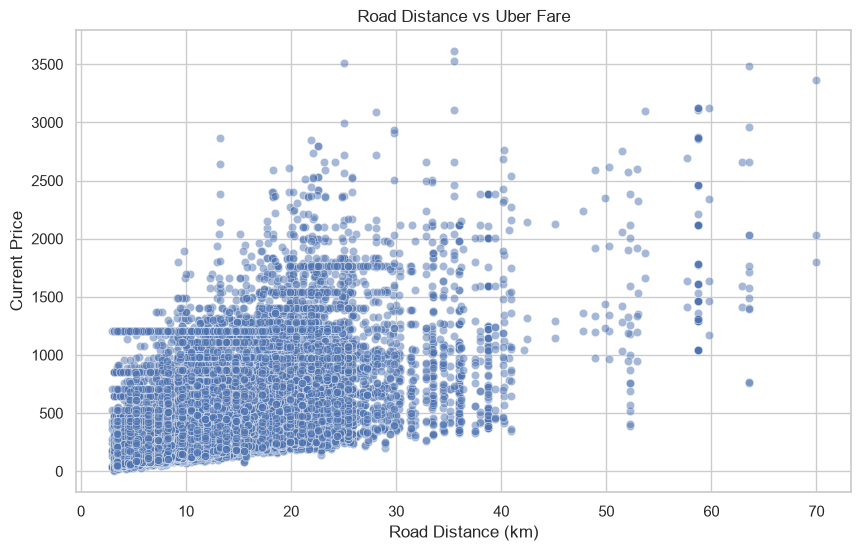

In [160]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="road_distance_km",
    y="current_price",
    alpha=0.5
)

plt.title("Road Distance vs Uber Fare")
plt.xlabel("Road Distance (km)")
plt.ylabel("Current Price")
plt.show()

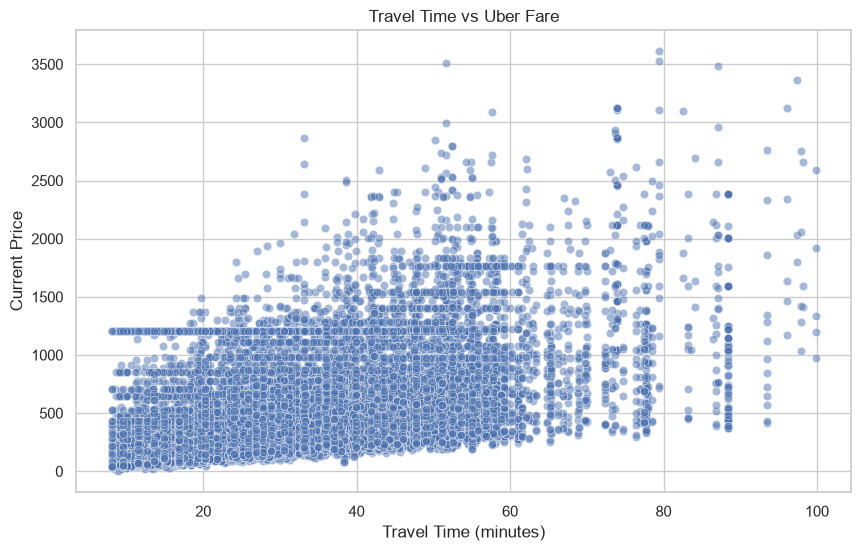

In [161]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="travel_time_minutes",
    y="current_price",
    alpha=0.5
)

plt.title("Travel Time vs Uber Fare")
plt.xlabel("Travel Time (minutes)")
plt.ylabel("Current Price")
plt.show()

### 4.1 Missing Numerical Features

The `seats` and `eta_minutes` variables contain missing values.
We investigate their distributions and missingness patterns before
deciding how they should be handled during feature engineering.

In [162]:
print("Seats statistics:")
print(df["seats"].describe())

print("\nETA statistics:")
print(df["eta_minutes"].describe())

Seats statistics:
count    11571.000000
mean         3.844612
std          1.607368
min          1.000000
25%          3.000000
50%          4.000000
75%          4.000000
max          6.000000
Name: seats, dtype: float64

ETA statistics:
count    14213.000000
mean         5.222050
std          2.578369
min          1.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         19.000000
Name: eta_minutes, dtype: float64


In [163]:
missing_by_ride = df.groupby("ride_name")[["seats", "eta_minutes"]].apply(
    lambda x: x.isnull().sum()
)

print("The rides represented as missing by ride: ")
print(missing_by_ride)

missing_percentage_by_ride = (
    df.groupby("ride_name")[["seats", "eta_minutes"]]
    .apply(lambda x: x.isnull().mean() * 100)
)

print("Percentage missing by ride: ")
print(missing_percentage_by_ride.round(2))

The rides represented as missing by ride: 
                 seats  eta_minutes
ride_name                          
Auto                 0            3
Auto Priority        0            2
Bike                 0           15
Bike Saver           0           15
Black                0          116
Black Rentals        0           63
Comfort              0            0
Electric             0            1
Go Intercity         0            0
Go Non AC            0            1
Go Priority          0            0
Go Rentals         938           16
Hatchback            0            7
Innova               0            8
Premier              0            0
Premier AC           0            5
Premier Rentals    938           18
Premier XL           0           33
Sedan                0            7
Uber Go AC           0            2
Uber Pet           938          104
UberXL               0           11
XL                   0           10
XL Plus Rentals      0          627
XL Rentals         93

In [164]:
ride_counts = df["ride_name"].value_counts()

ride_counts

ride_name
Uber Go AC         939
UberXL             939
Premier XL         939
Go Non AC          938
Auto               938
Bike Saver         938
Auto Priority      938
Bike               938
Uber Pet           938
Go Rentals         938
Premier Rentals    938
XL Rentals         938
Go Priority        935
Premier AC         924
XL Plus Rentals    922
Black              710
Black Rentals      282
Electric           150
Hatchback           32
Sedan               32
XL                  32
Premier             21
Innova              21
Go Intercity         2
Comfort              1
Name: count, dtype: int64

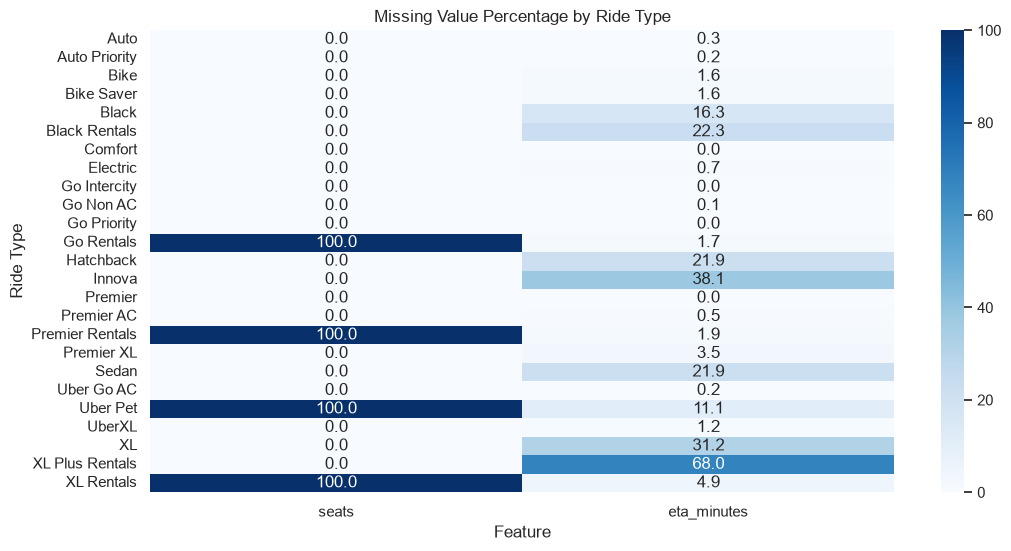

In [165]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    missing_percentage_by_ride,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Missing Value Percentage by Ride Type")
plt.xlabel("Feature")
plt.ylabel("Ride Type")
plt.show()

## 5. Categorical Feature Analysis

We examine the categorical variables to understand their frequency,
cardinality, and relationship with the target variable `current_price`.

The categorical features considered are:

- `ride_name`
- `pickup_category`
- `drop_category`

In [166]:
ride_counts = df["ride_name"].value_counts()

print("Number of unique ride types:", df["ride_name"].nunique())
print("\nRide type counts:")
print(ride_counts)

Number of unique ride types: 25

Ride type counts:
ride_name
Uber Go AC         939
UberXL             939
Premier XL         939
Go Non AC          938
Auto               938
Bike Saver         938
Auto Priority      938
Bike               938
Uber Pet           938
Go Rentals         938
Premier Rentals    938
XL Rentals         938
Go Priority        935
Premier AC         924
XL Plus Rentals    922
Black              710
Black Rentals      282
Electric           150
Hatchback           32
Sedan               32
XL                  32
Premier             21
Innova              21
Go Intercity         2
Comfort              1
Name: count, dtype: int64


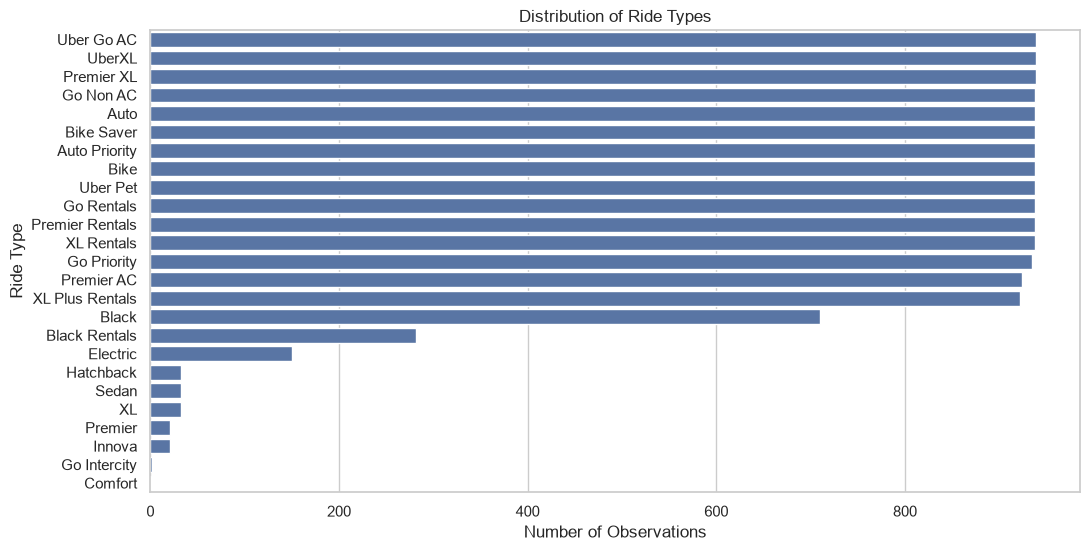

In [167]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="ride_name",
    order=ride_counts.index
)

plt.title("Distribution of Ride Types")
plt.xlabel("Number of Observations")
plt.ylabel("Ride Type")
plt.show()

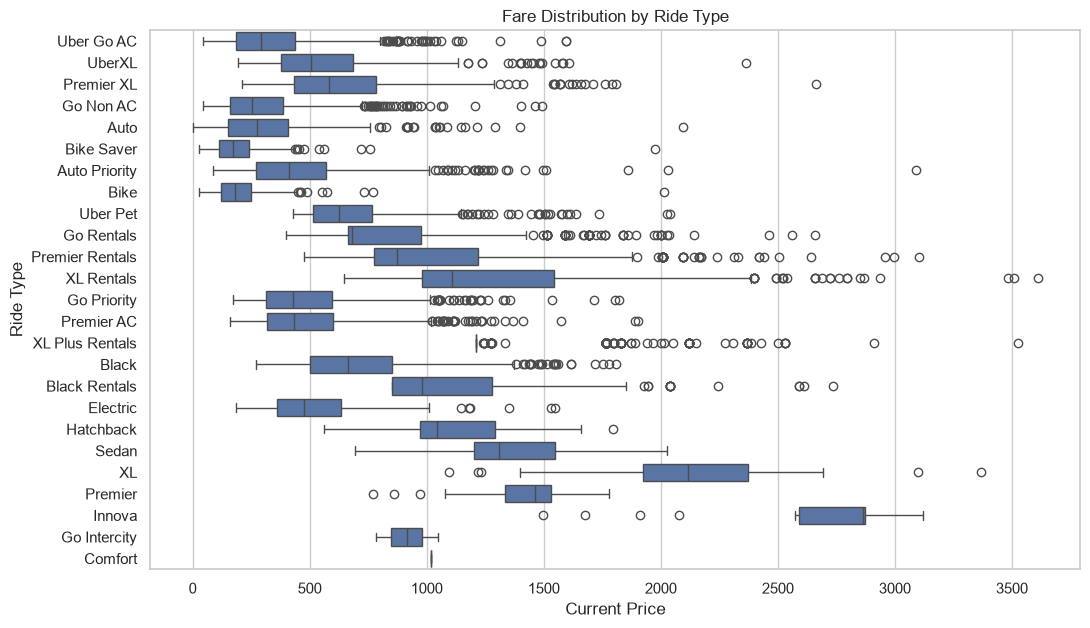

In [168]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="current_price",
    y="ride_name",
    order=ride_counts.index
)

plt.title("Fare Distribution by Ride Type")
plt.xlabel("Current Price")
plt.ylabel("Ride Type")
plt.show()

In [169]:
ride_fare_summary = (
    df.groupby("ride_name")["current_price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)

ride_fare_summary

,count,mean,median,std,min,max
ride_name,,,,,,
Innova,21,2663.348571,2862.330,479.300079,1496.27,3120.95
XL,32,2132.448750,2117.255,491.392138,1094.78,3368.61
Premier,21,1404.996190,1463.240,287.496724,772.14,1778.57
Sedan,32,1330.806875,1306.690,300.822885,692.16,2028.13
XL Plus Rentals,922,1321.016866,1208.650,276.492051,1208.65,3523.85
XL Rentals,938,1236.073614,1108.250,469.144220,645.00,3611.80
Hatchback,32,1104.693750,1043.485,272.481836,559.61,1796.45
Comfort,1,1016.730000,1016.730,NaN,1016.73,1016.73
Black Rentals,282,1148.578723,980.000,363.277712,850.00,2736.35


### 5.1 Pickup and Drop-off Categories

We now examine the categories assigned to pickup and drop-off locations
and investigate whether these categories are associated with different
fare levels.

In [170]:
pickup_category_counts = df["pickup_category"].value_counts()

print("Number of pickup categories:", df["pickup_category"].nunique())
pickup_category_counts

Number of pickup categories: 11


pickup_category
metro_station         3423
it_park               2033
mall                  1966
residential_area      1671
bus_terminal          1462
hospital              1367
hotel                 1124
college                815
railway_station        801
tourist_attraction     652
airport                  9
Name: count, dtype: int64

In [171]:
drop_category_counts = df["drop_category"].value_counts()

print("Number of drop-off categories:", df["drop_category"].nunique())
drop_category_counts

Number of drop-off categories: 10


drop_category
metro_station         3725
it_park               3291
residential_area      2371
mall                  1536
hotel                 1117
hospital               985
bus_terminal           851
college                710
railway_station        421
tourist_attraction     316
Name: count, dtype: int64

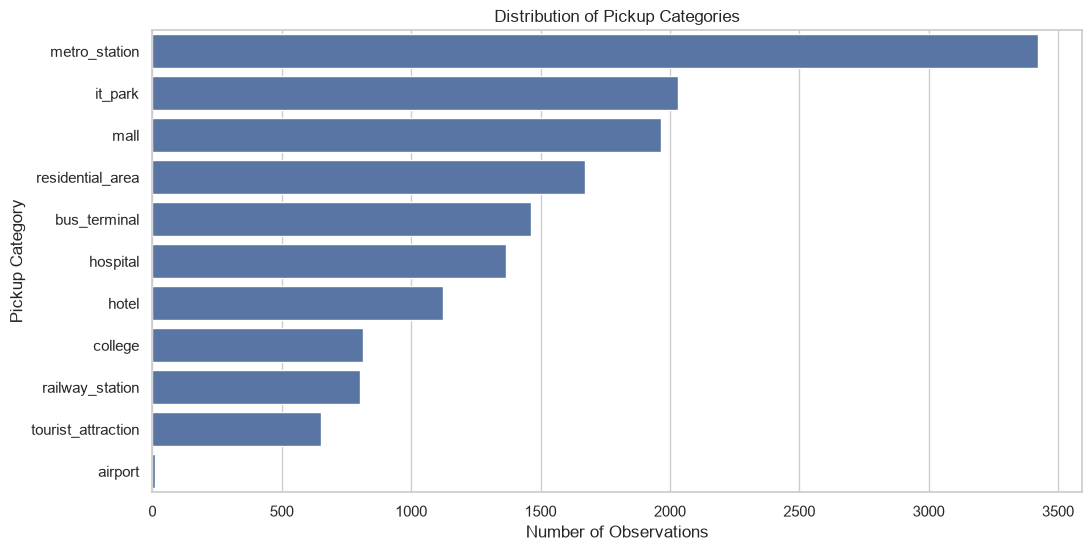

In [172]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="pickup_category",
    order=pickup_category_counts.index
)

plt.title("Distribution of Pickup Categories")
plt.xlabel("Number of Observations")
plt.ylabel("Pickup Category")
plt.show()

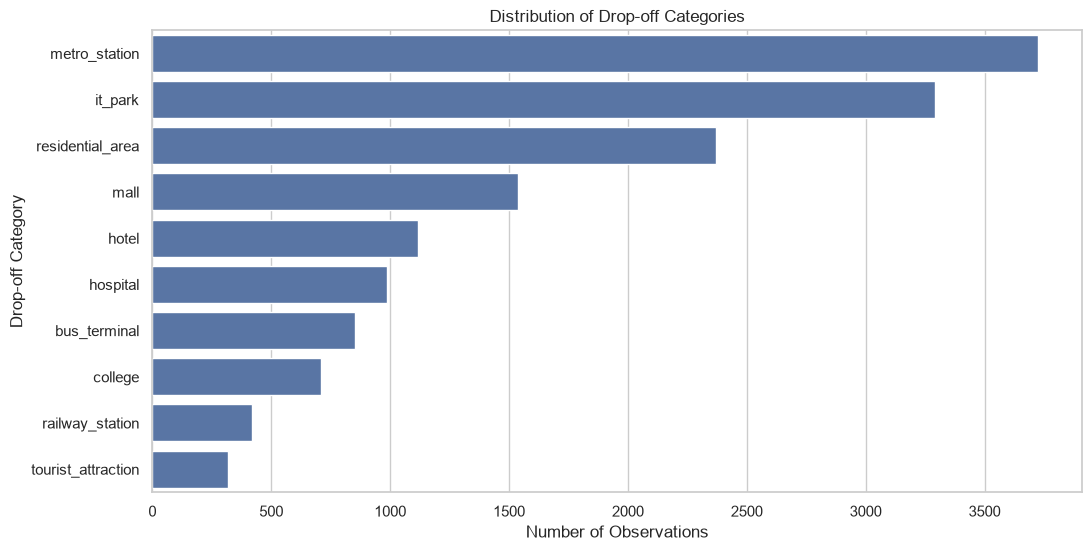

In [173]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="drop_category",
    order=drop_category_counts.index
)

plt.title("Distribution of Drop-off Categories")
plt.xlabel("Number of Observations")
plt.ylabel("Drop-off Category")
plt.show()

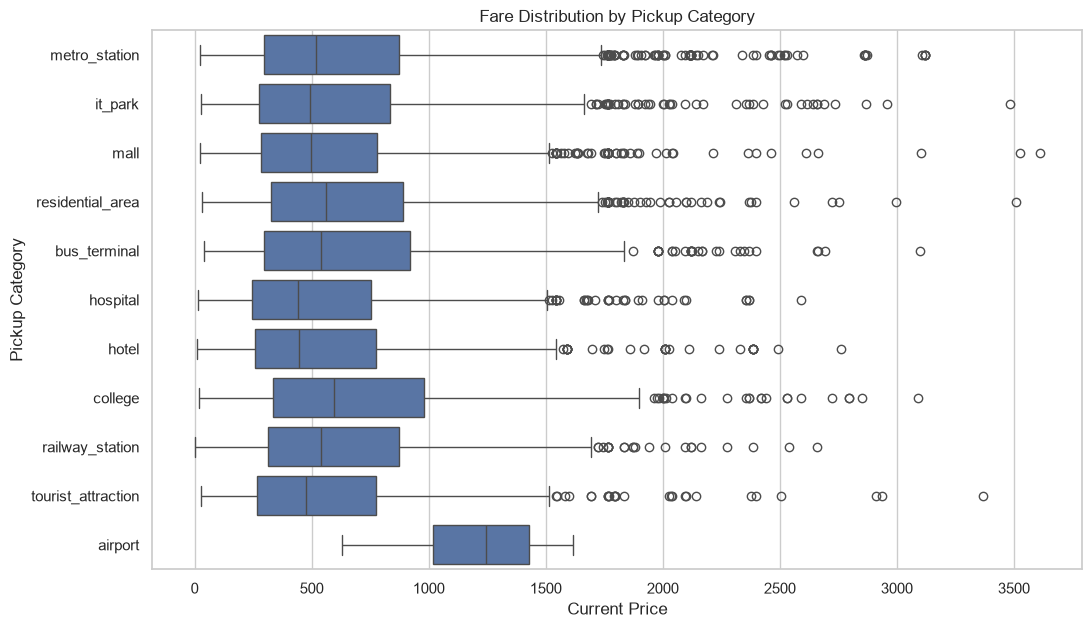

In [174]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="current_price",
    y="pickup_category",
    order=pickup_category_counts.index
)

plt.title("Fare Distribution by Pickup Category")
plt.xlabel("Current Price")
plt.ylabel("Pickup Category")
plt.show()

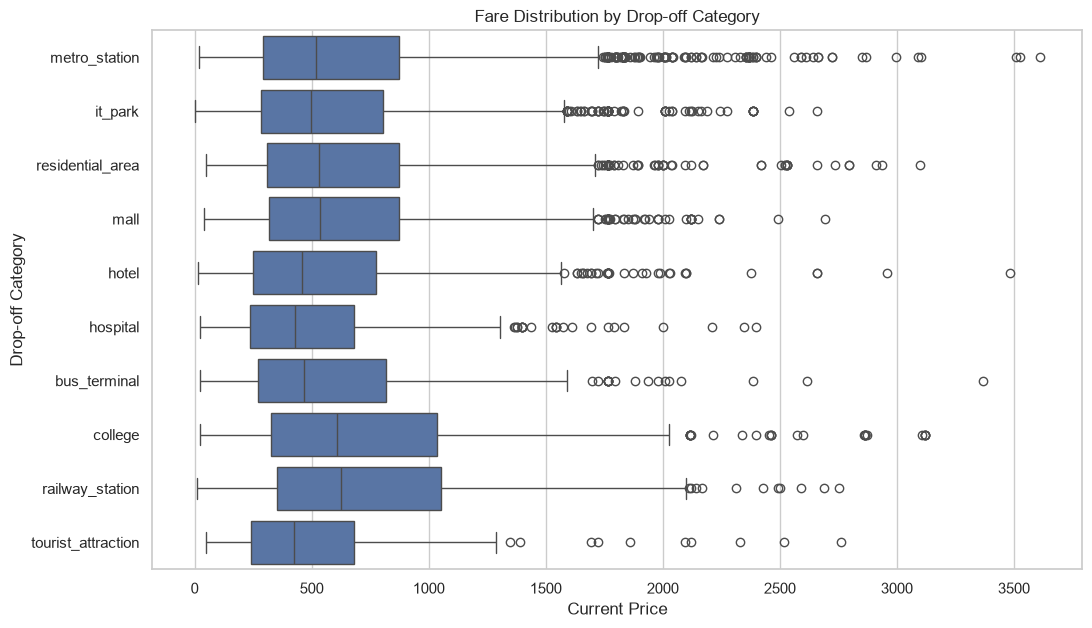

In [175]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="current_price",
    y="drop_category",
    order=drop_category_counts.index
)

plt.title("Fare Distribution by Drop-off Category")
plt.xlabel("Current Price")
plt.ylabel("Drop-off Category")
plt.show()

## 6. Temporal Analysis

Fare prices can vary with time of day and day of week. We analyze the
temporal distribution of the collected observations and investigate
whether `current_price` varies across different collection slots and days.

The analysis uses:

- `timestamp`
- `time_slot`
- `day_of_week`

In [176]:
print("Timestamp data type:", df["timestamp"].dtype)

print("\nEarliest observation:")
print(df["timestamp"].min())

print("\nLatest observation:")
print(df["timestamp"].max())

Timestamp data type: str

Earliest observation:
2026-08-30 16:22:06.459051+05:30

Latest observation:
2026-09-17 18:01:09.135888+05:30


In [177]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df["timestamp"].dtype)

datetime64[us, UTC+05:30]


In [178]:
slot_counts = (
    df["time_slot"]
    .value_counts()
    .sort_index()
)

slot_counts

time_slot
00:00    3583
09:00    3199
12:00     350
15:00    3273
18:00    2641
21:00    2277
Name: count, dtype: int64

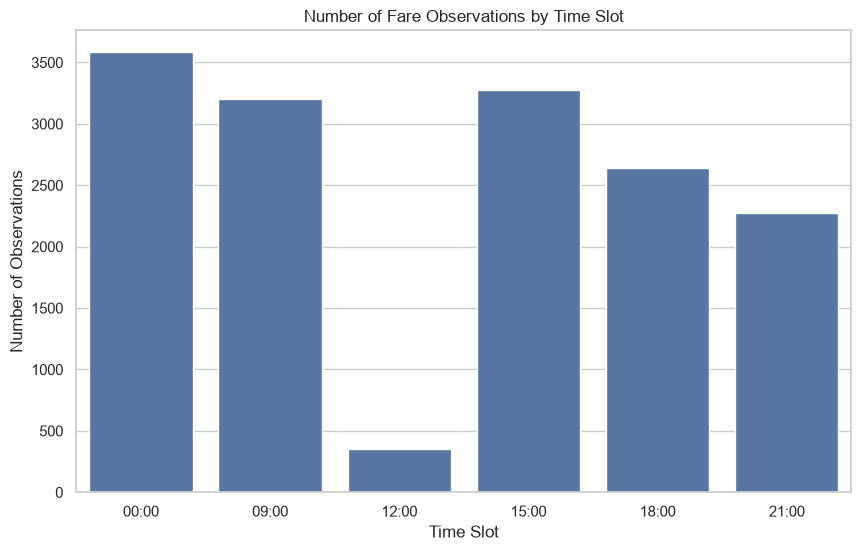

In [179]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=slot_counts.index,
    y=slot_counts.values
)

plt.title("Number of Fare Observations by Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Number of Observations")
plt.show()

In [180]:
slot_fare_summary = (
    df.groupby("time_slot")["current_price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

slot_fare_summary

,count,mean,median,std,min,max
time_slot,,,,,,
00:00,3583,596.884200,477.71,436.907676,21.33,3120.95
09:00,3199,648.396043,534.38,453.732658,0.00,3483.00
12:00,350,645.396400,535.32,453.774895,53.21,2860.61
15:00,3273,592.206942,491.04,405.442729,10.98,2753.71
18:00,2641,671.828966,551.05,487.187945,36.46,3611.80
21:00,2277,603.373874,481.07,459.031778,19.55,3509.30


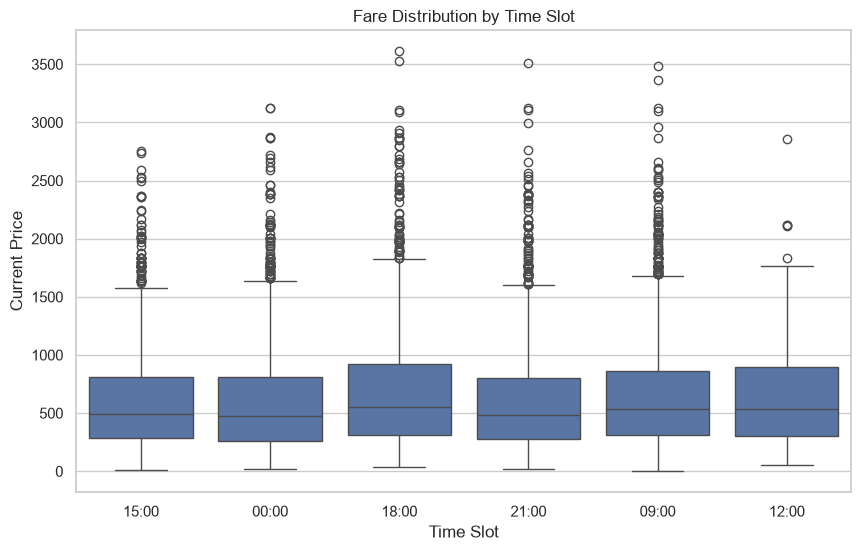

In [181]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="time_slot",
    y="current_price"
)

plt.title("Fare Distribution by Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Current Price")
plt.show()

In [182]:
day_counts = df["day_of_week"].value_counts()

day_counts

day_of_week
Thursday     4913
Tuesday      3380
Wednesday    3349
Monday       2468
Sunday       1055
Saturday      158
Name: count, dtype: int64

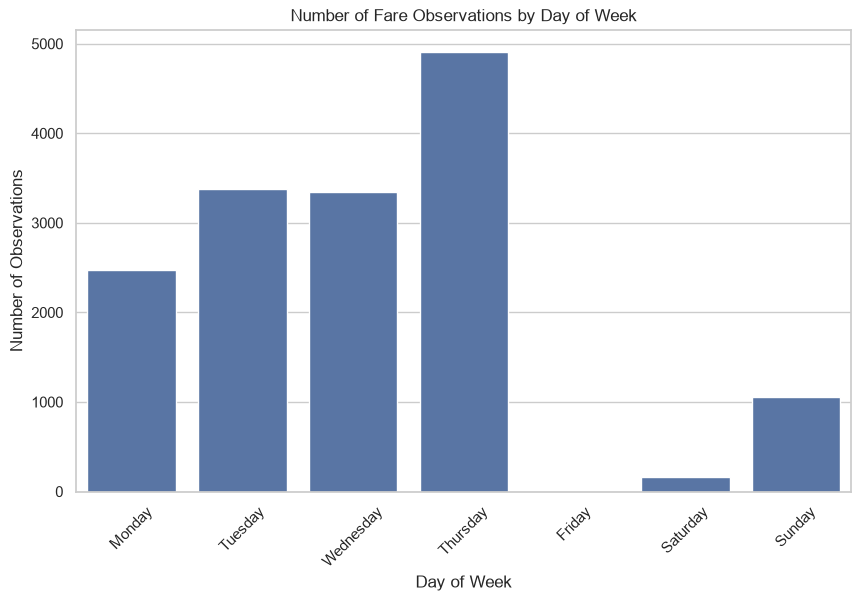

In [183]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="day_of_week",
    order=day_order
)

plt.title("Number of Fare Observations by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.show()

In [184]:
day_fare_summary = (
    df.groupby("day_of_week")["current_price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(day_order)
)

day_fare_summary

,count,mean,median,std,min,max
day_of_week,,,,,,
Monday,2468.0,611.681750,499.62,445.997284,37.60,3120.95
Tuesday,3380.0,621.325518,505.21,454.761912,14.66,3611.80
Wednesday,3349.0,621.078459,500.50,454.758577,0.00,3483.00
Thursday,4913.0,625.176623,519.02,434.507933,23.02,3368.61
Friday,NaN,NaN,NaN,NaN,NaN,NaN
Saturday,158.0,614.263608,561.90,361.471860,96.35,1765.90
Sunday,1055.0,632.199744,499.70,479.919152,44.13,3509.30


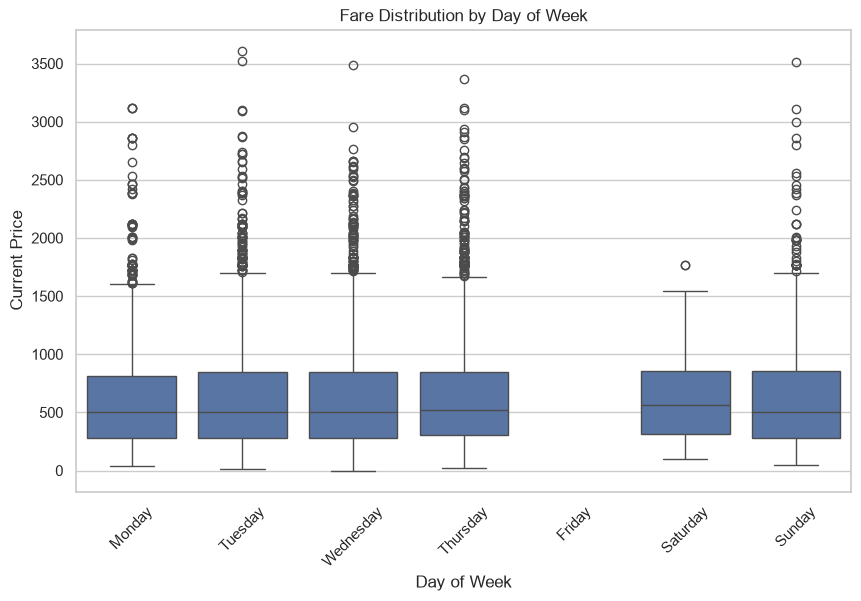

In [185]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="day_of_week",
    y="current_price",
    order=day_order
)

plt.title("Fare Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Current Price")
plt.xticks(rotation=45)
plt.show()

In [186]:
df["hour"] = df["timestamp"].dt.hour

df["hour"].value_counts().sort_index()

hour
0      547
2      368
3      361
4      658
5       77
6      780
7      387
8      405
9     3199
12     350
15     815
16    2458
18    2641
21     763
22     991
23     523
Name: count, dtype: int64

In [187]:
df["is_weekend"] = df["day_of_week"].isin(
    ["Saturday", "Sunday"]
)

df.groupby("is_weekend")["current_price"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
is_weekend,,,,
False,14110,620.921001,507.12,446.244326
True,1213,629.863462,505.80,466.110521


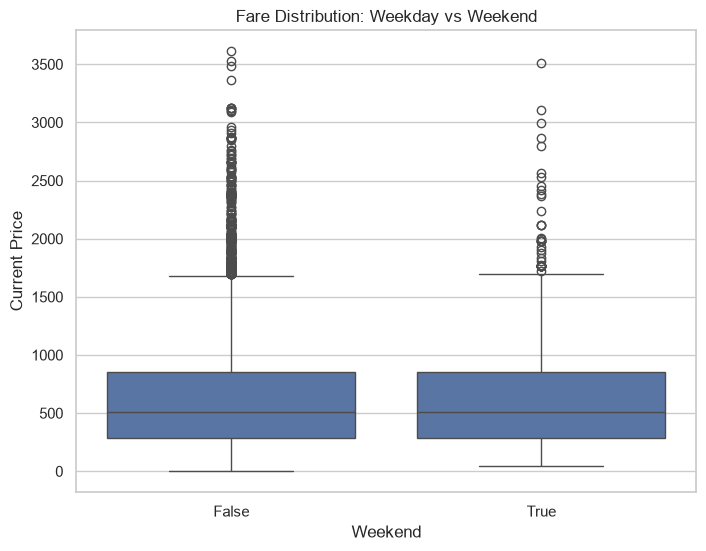

In [188]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="is_weekend",
    y="current_price"
)

plt.title("Fare Distribution: Weekday vs Weekend")
plt.xlabel("Weekend")
plt.ylabel("Current Price")
plt.show()

## 7. Route-Level Analysis

The dataset contains repeated fare observations for the same pickup and
drop-off routes. We analyze route coverage, observation frequency, and
route-level fare variation.

We also investigate the relationship between route characteristics
(`road_distance_km` and `travel_time_minutes`) and the observed fare.

In [189]:
df["route"] = (
    df["pickup"] + " → " + df["dropoff"]
)

print("Unique routes:", df["route"].nunique())

Unique routes: 750


In [190]:
route_counts = (
    df["route"]
    .value_counts()
)

route_counts.describe()

count    750.000000
mean      20.430667
std       16.416959
min        1.000000
25%       16.000000
50%       16.000000
75%       17.000000
max       84.000000
Name: count, dtype: float64

In [191]:
route_counts.head(20)

route
Mangammanapalya → Eden Bhavan                             84
Hopefarm Channasandra → Raheja Arcade                     84
Davanam Sarovar Portico Suites → Geethanjali Flora        83
Garuda Mall → MGM Mark                                    83
Sree Apartments → MGM Mark                                83
BMTC Hospital → Singayyanapalya                           83
Nexus Whitefield → Ottobock                               83
The Capitol → BMTC                                        82
CPR Arcade → Srirampura                                   82
Karnataka State Fisheries → BTM Layout                    82
Krishnarajapura → Gokulam Finance                         82
Amenities Hall → Hoodi                                    82
Halasuru → Nokia Care                                     82
Apurva Enthrall → Kundalahalli                            82
Sangolli Rayanna → Singasandra                            81
Channasandra → Divakars speciality Hospital               81
Apurva Enthrall → 

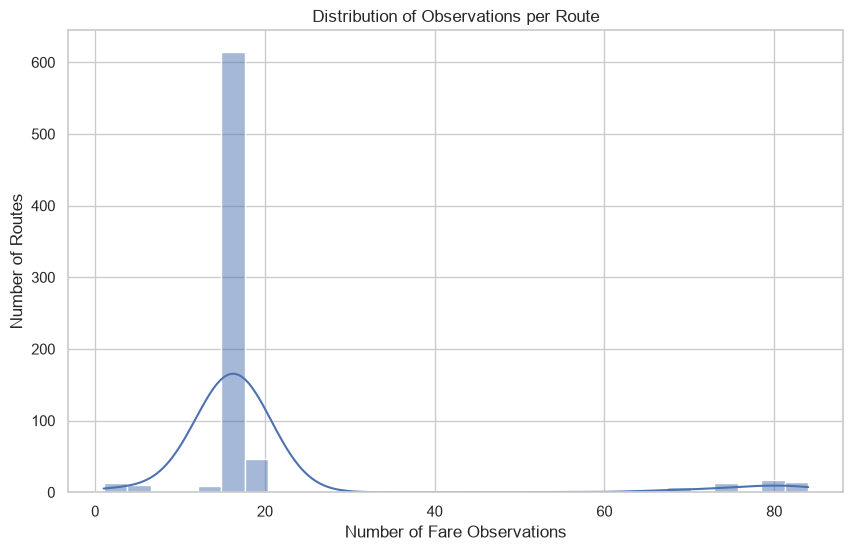

In [192]:
plt.figure(figsize=(10, 6))

sns.histplot(
    route_counts,
    bins=30,
    kde=True
)

plt.title("Distribution of Observations per Route")
plt.xlabel("Number of Fare Observations")
plt.ylabel("Number of Routes")
plt.show()

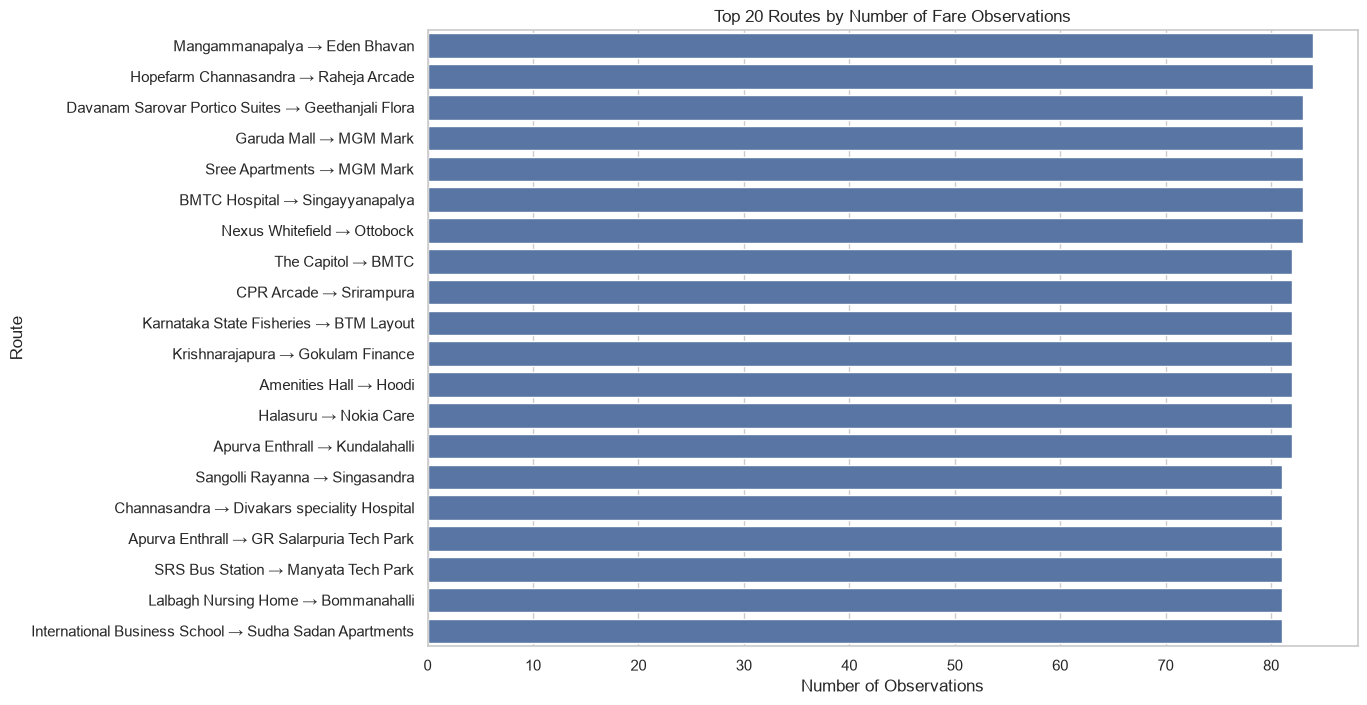

In [193]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=route_counts.head(20).values,
    y=route_counts.head(20).index
)

plt.title("Top 20 Routes by Number of Fare Observations")
plt.xlabel("Number of Observations")
plt.ylabel("Route")
plt.show()

In [194]:
route_fare_summary = (
    df.groupby("route")["current_price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)

route_fare_summary.head(20)

,count,mean,median,std,min,max
route,,,,,,
Muthyala Maduvu → Jalahalli Village,3,2397.730000,2028.130,848.749013,1796.45,3368.61
Nexus Whitefield → Madavara,15,2069.194667,1888.290,898.088546,717.94,3611.80
Harohalli Bus Stand → Corporate Stay,3,2210.593333,1873.540,776.381896,1659.70,3098.54
Light and Matter Physics → Delta Electronics Bommasandra,15,1658.930000,1760.000,693.296275,895.13,3091.10
Konark B45 → Angsana Oasis Spa & Resort,13,1848.588462,1716.060,796.143489,755.56,3483.00
Maralawadi → Manyavar Mohey,3,1914.173333,1640.530,684.393986,1408.94,2693.05
Baiyappanahalli → Ghousia College Of Engineering,5,1945.880000,1635.740,784.637697,1172.06,3120.10
Kudlu Gate → Ghousia College Of Engineering,55,1869.147091,1612.300,676.863879,1039.60,3120.95
Harohalli Bus Stand → Whitefield (Kadugodi),3,1890.816667,1596.170,674.148362,1414.15,2662.13


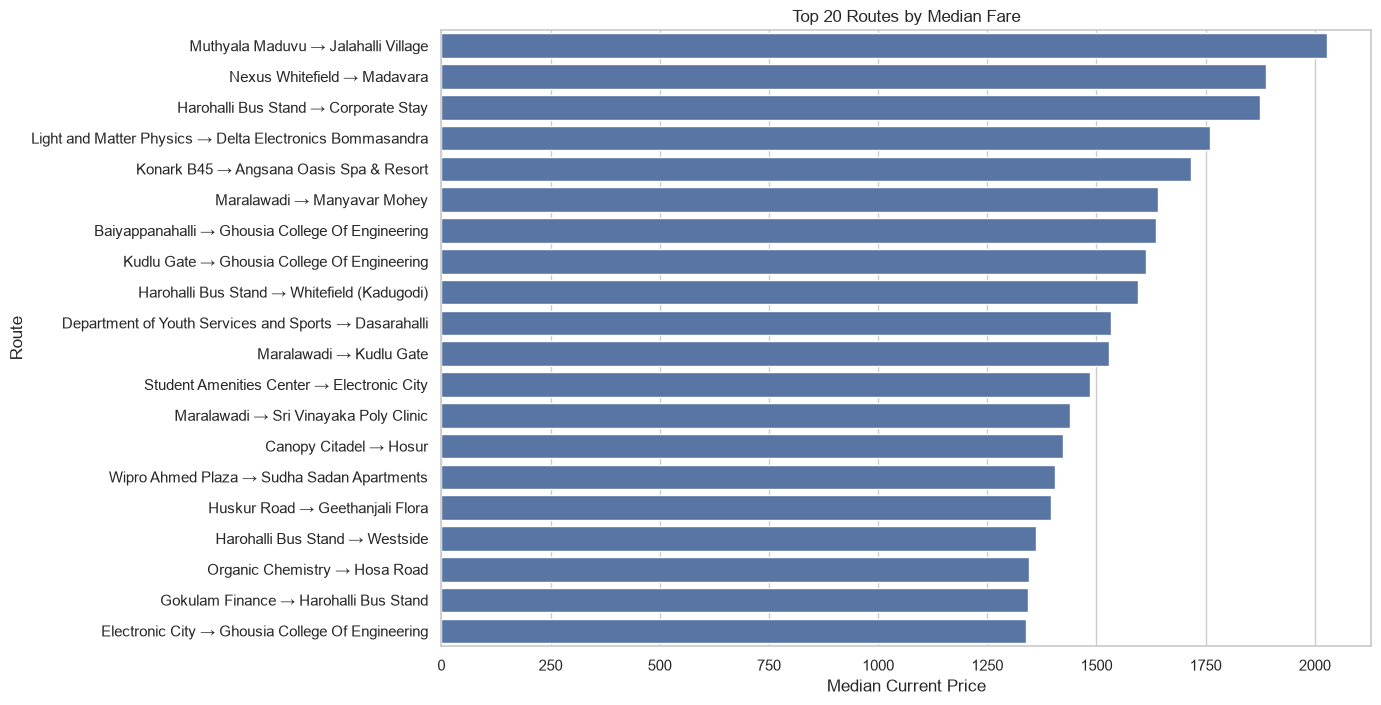

In [195]:
plt.figure(figsize=(12, 8))

top_routes = route_fare_summary.head(20)

sns.barplot(
    x=top_routes["median"],
    y=top_routes.index
)

plt.title("Top 20 Routes by Median Fare")
plt.xlabel("Median Current Price")
plt.ylabel("Route")
plt.show()

In [196]:
route_summary = (
    df.groupby("route")
    .agg(
        median_fare=("current_price", "median"),
        mean_fare=("current_price", "mean"),
        road_distance_km=("road_distance_km", "first"),
        travel_time_minutes=("travel_time_minutes", "first"),
        observations=("current_price", "count")
    )
    .reset_index()
)

route_summary.head()

,route,median_fare,mean_fare,road_distance_km,travel_time_minutes,observations
0,AGS Layout Bus Stand → Bougainvilla,694.85,724.938667,21.461,57.20,15
1,AGS Layout Bus Stand → Chikka Banavara,460.40,642.365333,23.450,51.06,15
2,AGS Layout Bus Stand → Gopalan Arcade Mall,240.10,318.457333,6.267,16.05,15
3,AGS Layout Bus Stand → House no 279,600.26,745.449600,22.303,54.58,75
4,AGS Layout Bus Stand → JBS Hospital,254.26,330.493867,5.856,15.94,75


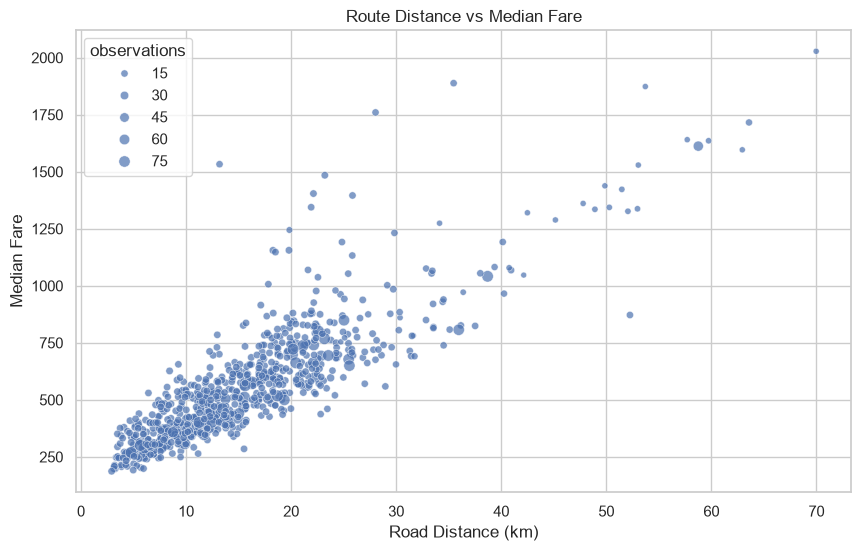

In [197]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=route_summary,
    x="road_distance_km",
    y="median_fare",
    size="observations",
    alpha=0.7
)

plt.title("Route Distance vs Median Fare")
plt.xlabel("Road Distance (km)")
plt.ylabel("Median Fare")
plt.show()

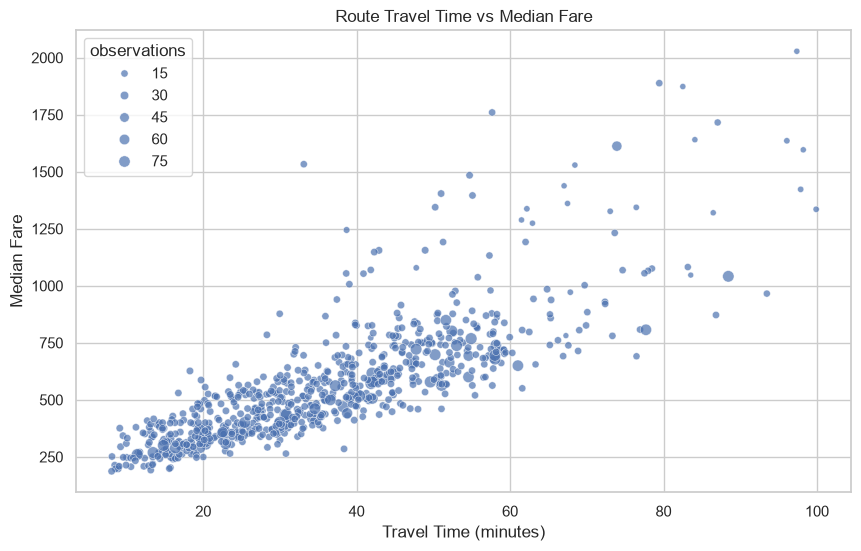

In [198]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=route_summary,
    x="travel_time_minutes",
    y="median_fare",
    size="observations",
    alpha=0.7
)

plt.title("Route Travel Time vs Median Fare")
plt.xlabel("Travel Time (minutes)")
plt.ylabel("Median Fare")
plt.show()

## 8. Day and Time Interaction Analysis

Fare patterns may depend on both the day of the week and the time of day.
We therefore examine the interaction between `day_of_week` and `time_slot`.

This helps determine whether temporal features should be represented
individually or through additional combinations during feature engineering.

In [199]:
day_slot_counts = pd.crosstab(
    df["day_of_week"],
    df["time_slot"]
).reindex(day_order)

day_slot_counts

time_slot,00:00,09:00,12:00,15:00,18:00,21:00
day_of_week,,,,,,
Monday,1023.0,400.0,350.0,0.0,375.0,320.0
Tuesday,1094.0,399.0,0.0,801.0,362.0,724.0
Wednesday,983.0,773.0,0.0,815.0,15.0,763.0
Thursday,326.0,1544.0,0.0,1561.0,1482.0,0.0
Friday,NaN,NaN,NaN,NaN,NaN,NaN
Saturday,16.0,0.0,0.0,0.0,0.0,142.0
Sunday,141.0,83.0,0.0,96.0,407.0,328.0


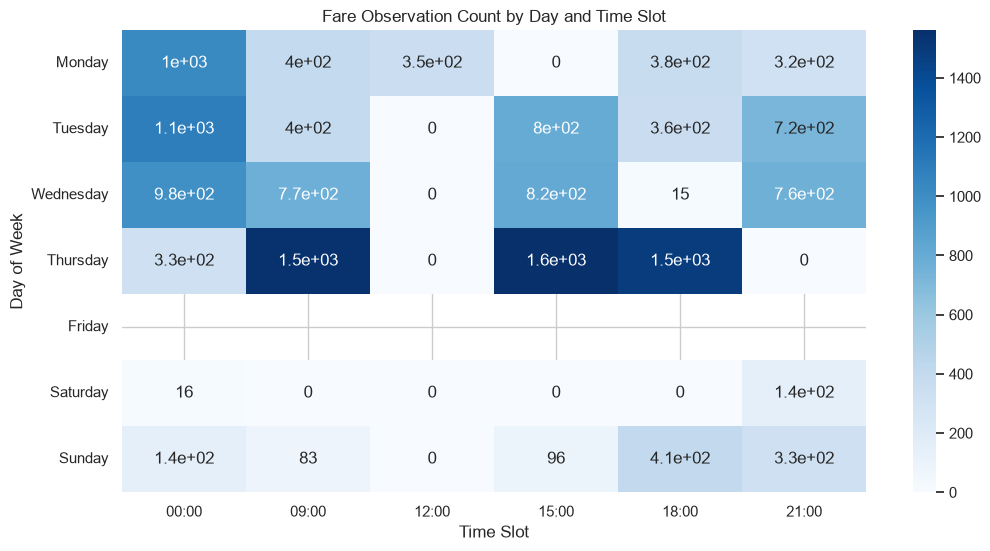

In [200]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    day_slot_counts,
    annot=True,
    cmap="Blues"
)

plt.title("Fare Observation Count by Day and Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Day of Week")
plt.show()

In [201]:
day_slot_fare = (
    df.groupby(["day_of_week", "time_slot"])["current_price"]
    .median()
    .unstack()
    .reindex(day_order)
)

day_slot_fare

time_slot,00:00,09:00,12:00,15:00,18:00,21:00
day_of_week,,,,,,
Monday,454.530,483.335,535.32,NaN,529.640,577.895
Tuesday,536.965,499.370,NaN,512.420,668.915,424.365
Wednesday,460.420,611.700,NaN,497.490,353.170,463.760
Thursday,444.965,530.990,NaN,481.310,552.985,NaN
Friday,NaN,NaN,NaN,NaN,NaN,NaN
Saturday,618.635,NaN,NaN,NaN,NaN,561.600
Sunday,470.510,390.690,NaN,428.765,477.630,589.665


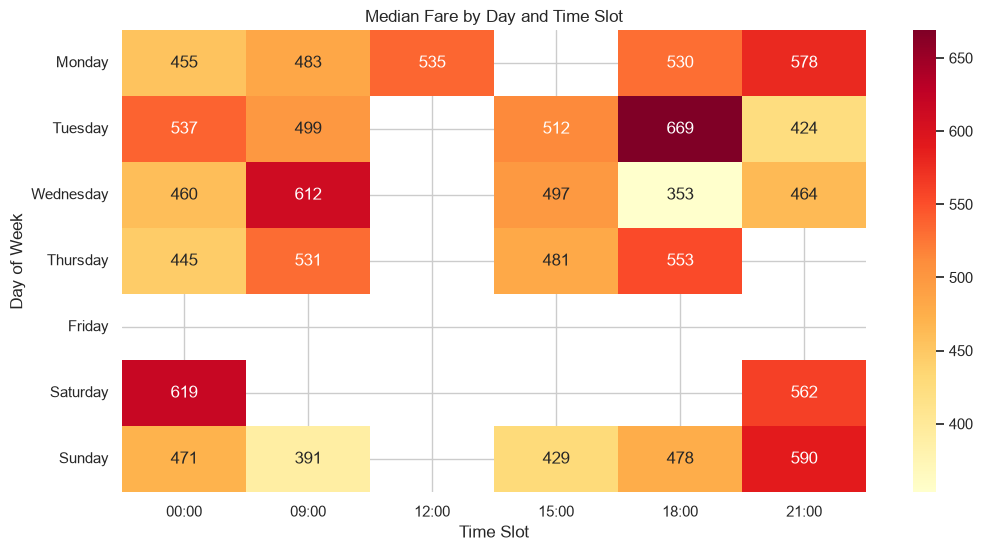

In [202]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    day_slot_fare,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Median Fare by Day and Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Day of Week")
plt.show()

In [203]:
ride_slot_fare = (
    df.groupby(["ride_name", "time_slot"])["current_price"]
    .median()
    .unstack()
)

ride_slot_fare

time_slot,00:00,09:00,12:00,15:00,18:00,21:00
ride_name,,,,,,
Auto,328.490,263.060,332.120,197.930,261.030,323.530
Auto Priority,512.560,382.400,485.100,307.580,398.980,463.680
Bike,182.180,201.740,212.905,166.680,181.700,171.070
Bike Saver,177.060,195.050,202.065,159.440,173.370,164.880
Black,689.370,713.645,687.060,624.580,732.770,574.595
Black Rentals,1280.000,1175.000,1065.000,915.000,NaN,NaN
Comfort,NaN,NaN,NaN,1016.730,NaN,NaN
Electric,447.610,548.700,622.785,504.830,601.435,435.980
Go Intercity,NaN,NaN,NaN,781.640,1047.010,NaN


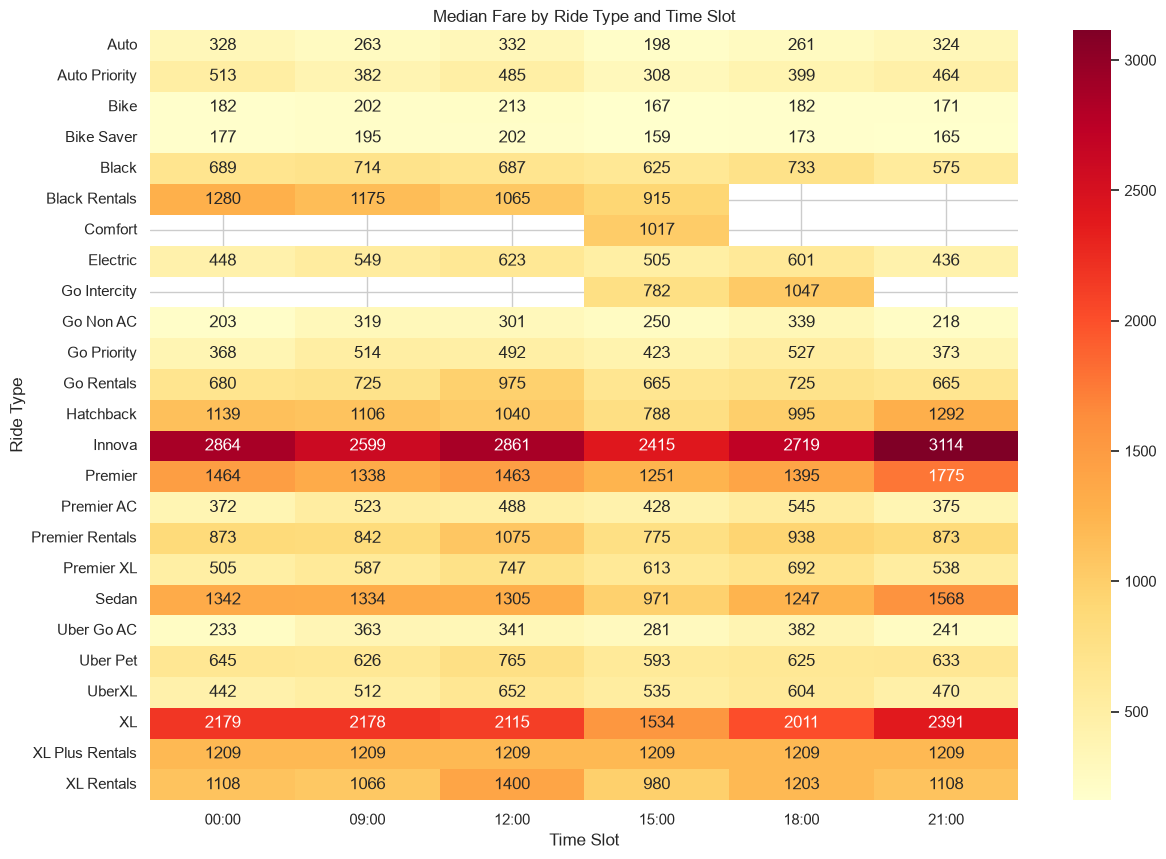

In [204]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    ride_slot_fare,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Median Fare by Ride Type and Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Ride Type")
plt.show()

## 9. Outlier Analysis

We investigate unusually high and low fare observations using statistical
methods and contextual information.

Statistical outliers are not automatically removed because extreme fares
may represent legitimate observations caused by route characteristics,
ride type, or temporal conditions.

In [205]:
Q1 = df["current_price"].quantile(0.25)
Q3 = df["current_price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 287.635
Q3: 850.0
IQR: 562.365
Lower bound: -555.9125
Upper bound: 1693.5475000000001


In [206]:
outlier_mask = (
    (df["current_price"] < lower_bound) |
    (df["current_price"] > upper_bound)
)

print("Potential outliers:", outlier_mask.sum())
print(
    "Percentage of observations:",
    round(outlier_mask.mean() * 100, 2),
    "%"
)

Potential outliers: 457
Percentage of observations: 2.98 %


In [207]:
df.loc[
    outlier_mask,
    [
        "timestamp",
        "time_slot",
        "day_of_week",
        "pickup",
        "dropoff",
        "pickup_category",
        "drop_category",
        "road_distance_km",
        "travel_time_minutes",
        "ride_name",
        "current_price"
    ]
].sort_values(
    "current_price",
    ascending=False
).head(20)

,timestamp,time_slot,day_of_week,pickup,dropoff,pickup_category,drop_category,road_distance_km,travel_time_minutes,ride_name,current_price
6203,2026-09-15 18:25:18.128381+05:30,18:00,Tuesday,Nexus Whitefield,Madavara,mall,metro_station,35.464,79.45,XL Rentals,3611.80
6201,2026-09-15 18:25:18.128381+05:30,18:00,Tuesday,Nexus Whitefield,Madavara,mall,metro_station,35.464,79.45,XL Plus Rentals,3523.85
1050,2026-09-13 22:25:12.455907+05:30,21:00,Sunday,Sudha Sadan Apartments,Huskur Road,residential_area,metro_station,25.030,51.63,XL Rentals,3509.30
8404,2026-09-16 09:01:26.537117+05:30,09:00,Wednesday,Konark B45,Angsana Oasis Spa & Resort,it_park,hotel,63.577,87.06,XL Rentals,3483.00
11364,2026-09-17 09:00:05.818218+05:30,09:00,Thursday,Muthyala Maduvu,Jalahalli Village,tourist_attraction,bus_terminal,69.969,97.38,XL,3368.61
1247,2026-09-14 00:15:45.211649+05:30,00:00,Monday,Kudlu Gate,Ghousia College Of Engineering,metro_station,college,58.752,73.92,Innova,3120.95
1537,2026-09-14 03:02:05.925735+05:30,00:00,Monday,Kudlu Gate,Ghousia College Of Engineering,metro_station,college,58.752,73.92,Innova,3120.60
3395,2026-09-14 22:08:44.187432+05:30,21:00,Monday,Kudlu Gate,Ghousia College Of Engineering,metro_station,college,58.752,73.92,Innova,3120.36
11402,2026-09-17 09:00:05.818218+05:30,09:00,Thursday,Baiyappanahalli,Ghousia College Of Engineering,metro_station,college,59.734,96.08,Innova,3120.10
964,2026-09-13 22:25:12.455907+05:30,21:00,Sunday,Kudlu Gate,Ghousia College Of Engineering,metro_station,college,58.752,73.92,Innova,3108.39


In [208]:
df["is_potential_outlier"] = outlier_mask

df.groupby("is_potential_outlier")[
    [
        "road_distance_km",
        "travel_time_minutes",
        "current_price"
    ]
].agg(["count", "mean", "median"])

road_distance_km                    travel_time_minutes  \
                                count       mean  median               count   
is_potential_outlier                                                           
False                           14866  15.074829  14.145               14866   
True                              457  29.738945  25.065                 457   

                                       current_price                        
                           mean median         count         mean   median  
is_potential_outlier                                                        
False                 35.395098  34.23         14866   577.624058   493.37  
True                  59.434573  55.79           457  2053.086324  1909.22

In [209]:
outliers_by_ride = (
    df.groupby("ride_name")["is_potential_outlier"]
    .agg(["count", "sum"])
)

outliers_by_ride["outlier_percentage"] = (
    outliers_by_ride["sum"] /
    outliers_by_ride["count"] * 100
)

outliers_by_ride.sort_values(
    "outlier_percentage",
    ascending=False
)

,count,sum,outlier_percentage
ride_name,,,
Innova,21,19,90.476190
XL,32,27,84.375000
Premier,21,4,19.047619
XL Plus Rentals,922,146,15.835141
XL Rentals,938,118,12.579957
Black Rentals,282,21,7.446809
Sedan,32,2,6.250000
Premier Rentals,938,58,6.183369
Go Rentals,938,37,3.944563


## 9.5 Investigating Zero-Fare Observations

The target variable `current_price` contains observations with a fare of ₹0.

A zero fare may represent either a legitimate special-case fare or a data-collection/parsing issue. Therefore, these observations should not be removed solely because their value is unusual.

Before model training, zero-fare observations will be inspected to determine whether they represent valid Uber fare observations or potential data-quality issues.

This analysis will help determine whether zero-fare observations should be retained or excluded from the final machine-learning dataset.

## 10. Deeper Missing-Value Analysis

The dataset contains missing values in `seats` and `eta_minutes`.
We investigate whether missingness is associated with ride type, time slot,
or other categorical variables.

This analysis will guide the treatment of missing values during
feature engineering.

In [210]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=False
)

missing_summary

,missing_count,missing_percentage
seats,3752,24.486067
eta_minutes,1110,7.244012


In [211]:
missing_ride_analysis = (
    df.groupby("ride_name")
    .agg(
        observations=("ride_name", "size"),
        missing_seats=("seats", lambda x: x.isna().sum()),
        missing_eta=("eta_minutes", lambda x: x.isna().sum())
    )
)

missing_ride_analysis["seats_missing_pct"] = (
    missing_ride_analysis["missing_seats"]
    / missing_ride_analysis["observations"] * 100
)

missing_ride_analysis["eta_missing_pct"] = (
    missing_ride_analysis["missing_eta"]
    / missing_ride_analysis["observations"] * 100
)

missing_ride_analysis.sort_values(
    "observations",
    ascending=False
)

,observations,missing_seats,missing_eta,seats_missing_pct,eta_missing_pct
ride_name,,,,,
UberXL,939,0,11,0.0,1.171459
Uber Go AC,939,0,2,0.0,0.212993
Premier XL,939,0,33,0.0,3.514377
Auto,938,0,3,0.0,0.319829
Go Non AC,938,0,1,0.0,0.106610
Uber Pet,938,938,104,100.0,11.087420
Premier Rentals,938,938,18,100.0,1.918977
Auto Priority,938,0,2,0.0,0.213220
Go Rentals,938,938,16,100.0,1.705757


In [212]:
missing_slot_analysis = (
    df.groupby("time_slot")
    .agg(
        observations=("time_slot", "size"),
        missing_seats=("seats", lambda x: x.isna().sum()),
        missing_eta=("eta_minutes", lambda x: x.isna().sum())
    )
)

missing_slot_analysis["seats_missing_pct"] = (
    missing_slot_analysis["missing_seats"]
    / missing_slot_analysis["observations"] * 100
)

missing_slot_analysis["eta_missing_pct"] = (
    missing_slot_analysis["missing_eta"]
    / missing_slot_analysis["observations"] * 100
)

missing_slot_analysis

,observations,missing_seats,missing_eta,seats_missing_pct,eta_missing_pct
time_slot,,,,,
00:00,3583,884,249,24.672063,6.949484
09:00,3199,760,331,23.757424,10.346983
12:00,350,88,22,25.142857,6.285714
15:00,3273,788,265,24.075771,8.096548
18:00,2641,660,148,24.990534,5.603938
21:00,2277,572,95,25.120773,4.172156


In [213]:
missing_day_analysis = (
    df.groupby("day_of_week")
    .agg(
        observations=("day_of_week", "size"),
        missing_seats=("seats", lambda x: x.isna().sum()),
        missing_eta=("eta_minutes", lambda x: x.isna().sum())
    )
    .reindex(day_order)
)

missing_day_analysis["seats_missing_pct"] = (
    missing_day_analysis["missing_seats"]
    / missing_day_analysis["observations"] * 100
)

missing_day_analysis["eta_missing_pct"] = (
    missing_day_analysis["missing_eta"]
    / missing_day_analysis["observations"] * 100
)

missing_day_analysis

,observations,missing_seats,missing_eta,seats_missing_pct,eta_missing_pct
day_of_week,,,,,
Monday,2468.0,604.0,143.0,24.473258,5.794165
Tuesday,3380.0,831.0,242.0,24.585799,7.159763
Wednesday,3349.0,824.0,256.0,24.604360,7.644073
Thursday,4913.0,1192.0,410.0,24.262162,8.345207
Friday,NaN,NaN,NaN,NaN,NaN
Saturday,158.0,40.0,2.0,25.316456,1.265823
Sunday,1055.0,261.0,57.0,24.739336,5.402844


In [214]:
df["seats_missing"] = df["seats"].isna()
df["eta_missing"] = df["eta_minutes"].isna()

df.groupby("seats_missing")["current_price"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
seats_missing,,,,
False,11571,522.711036,405.08,407.981509
True,3752,926.687180,840.00,427.273492


In [215]:
df.groupby("eta_missing")["current_price"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
eta_missing,,,,
False,14213,578.659401,475.07,417.544355
True,1110,1171.832099,1208.65,458.322795


## 11. Feature Relationship Analysis

We examine important relationships between the available features and
the target variable. The goal is to identify potentially useful
predictors, interactions, and sources of redundancy before feature
engineering.

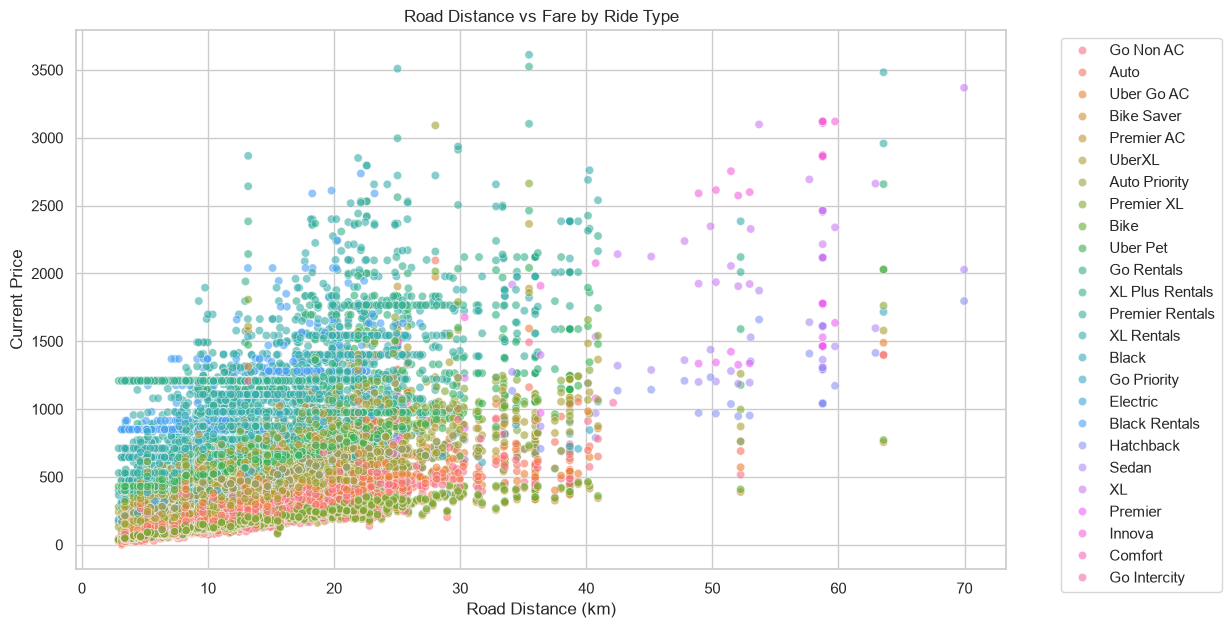

In [216]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="road_distance_km",
    y="current_price",
    hue="ride_name",
    alpha=0.6
)

plt.title("Road Distance vs Fare by Ride Type")
plt.xlabel("Road Distance (km)")
plt.ylabel("Current Price")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

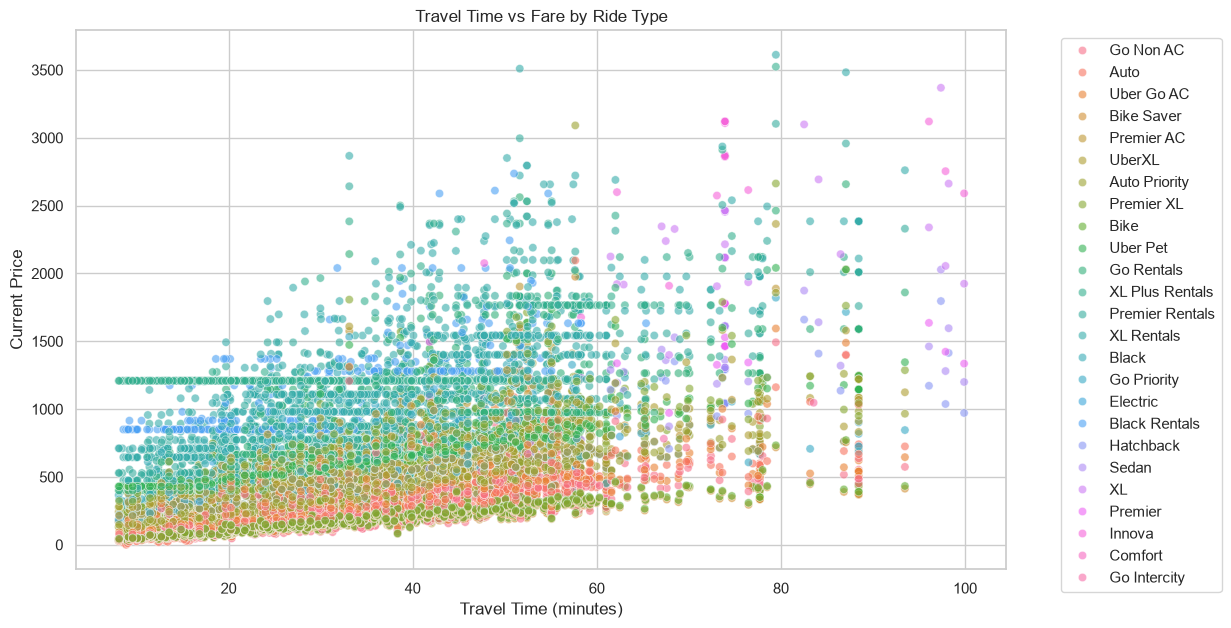

In [217]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="travel_time_minutes",
    y="current_price",
    hue="ride_name",
    alpha=0.6
)

plt.title("Travel Time vs Fare by Ride Type")
plt.xlabel("Travel Time (minutes)")
plt.ylabel("Current Price")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

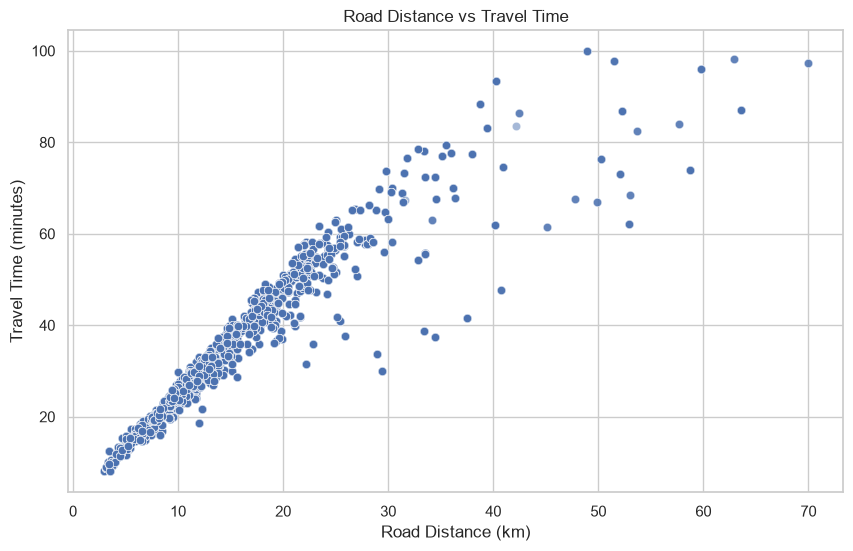

In [218]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="road_distance_km",
    y="travel_time_minutes",
    alpha=0.5
)

plt.title("Road Distance vs Travel Time")
plt.xlabel("Road Distance (km)")
plt.ylabel("Travel Time (minutes)")
plt.show()

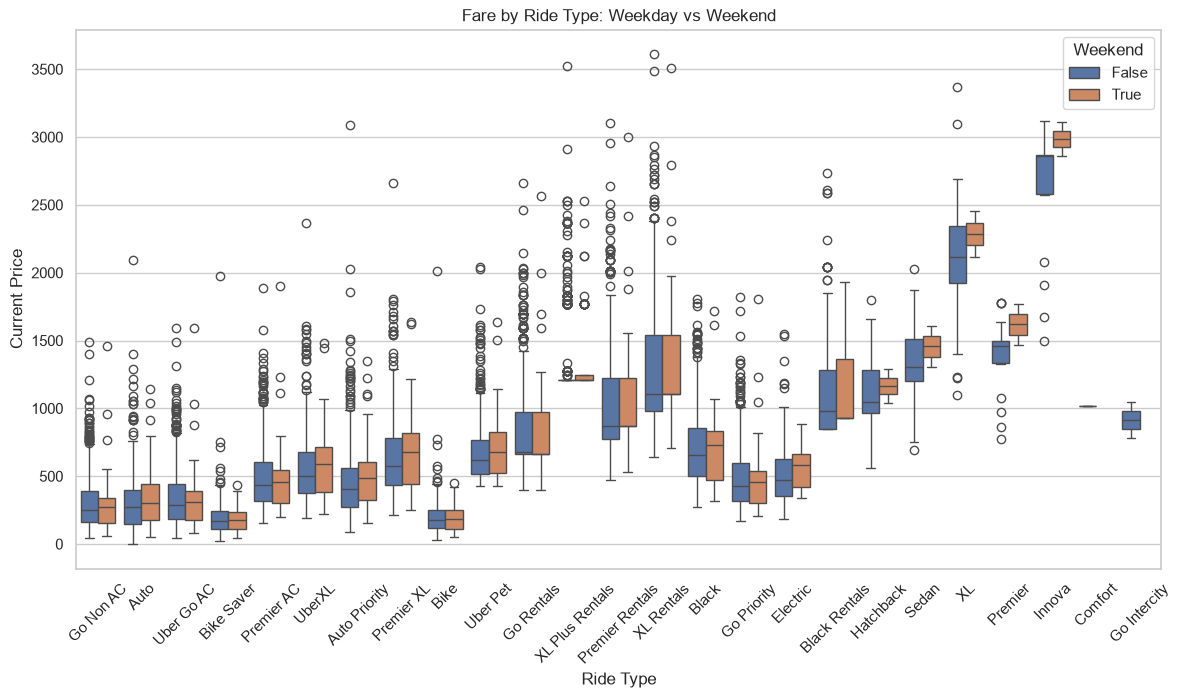

In [219]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="ride_name",
    y="current_price",
    hue="is_weekend"
)

plt.title("Fare by Ride Type: Weekday vs Weekend")
plt.xlabel("Ride Type")
plt.ylabel("Current Price")
plt.xticks(rotation=45)
plt.legend(title="Weekend")

plt.show()

In [220]:
ride_slot_mean = (
    df.groupby(["ride_name", "time_slot"])["current_price"]
    .mean()
    .unstack()
)

ride_slot_mean

time_slot,00:00,09:00,12:00,15:00,18:00,21:00
ride_name,,,,,,
Auto,351.639955,274.216211,320.043182,241.132437,290.029394,370.505944
Auto Priority,530.767557,403.442632,472.677273,369.169594,448.609030,509.524056
Bike,189.138552,206.554789,207.419091,185.572335,203.246364,182.057063
Bike Saver,182.524208,200.411105,196.931818,179.440964,196.756909,175.090699
Black,722.328024,748.718733,621.492857,661.213937,809.692812,623.246939
Black Rentals,1245.450000,1189.034127,1153.250000,1089.225591,NaN,NaN
Comfort,NaN,NaN,NaN,1016.730000,NaN,NaN
Electric,436.520000,582.651707,549.386667,507.298333,659.853500,455.191333
Go Intercity,NaN,NaN,NaN,781.640000,1047.010000,NaN


In [221]:
target_correlations = (
    df[numeric_columns]
    .corr()["current_price"]
    .sort_values(ascending=False)
)

target_correlations

current_price          1.000000
seats                  0.537944
road_distance_km       0.473918
travel_time_minutes    0.447457
eta_minutes            0.160792
Name: current_price, dtype: float64

## 12. Feature Engineering Decisions

Based on the exploratory analysis of the expanded dataset, we now determine which variables should be retained, transformed, encoded, or excluded from the machine-learning dataset.

The dataset now contains 15,323 fare observations, 231 unique pickup locations, 214 unique drop-off locations, and 750 unique routes.

The decisions consider:

- Relationship with the target variable
- Data quality and missingness
- Feature cardinality
- Temporal information
- Potential redundancy
- Prediction-time availability
- Potential data leakage
- Generalization and overfitting risk

In [222]:
feature_decisions = pd.DataFrame({
    "Feature": [
        "road_distance_km",
        "travel_time_minutes",
        "ride_name",
        "pickup_category",
        "drop_category",
        "time_slot",
        "day_of_week",
        "hour",
        "is_weekend",
        "seats",
        "eta_minutes",
        "pickup",
        "dropoff",
        "route"
    ],
    "Type": [
        "Numerical",
        "Numerical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Numerical",
        "Binary",
        "Numerical",
        "Numerical",
        "High-cardinality categorical",
        "High-cardinality categorical",
        "High-cardinality categorical"
    ]
})

feature_decisions

,Feature,Type
0,road_distance_km,Numerical
1,travel_time_minutes,Numerical
2,ride_name,Categorical
3,pickup_category,Categorical
4,drop_category,Categorical
5,time_slot,Categorical
6,day_of_week,Categorical
7,hour,Numerical
8,is_weekend,Binary
9,seats,Numerical


### 12.1 Feature Selection Considerations

The following considerations will guide the final feature-engineering pipeline:

1. Route characteristics such as road distance and travel time describe the trip itself and are potential predictors of fare.

2. Ride type is expected to be important because different Uber ride types have different fare structures.

3. Temporal variables such as time slot and day of week capture changes in pricing conditions over time.

4. Pickup and drop-off categories may provide additional contextual information about the trip.

5. Pickup and drop-off location names contain more specific location information than their corresponding categories. Their cardinality is manageable in the current dataset, but their encoding must still be handled carefully to avoid overfitting.

6. Route is a high-cardinality representation of the pickup-drop-off combination. Although it may contain useful route-specific pricing information, its benefit should be evaluated using model validation rather than decided solely from EDA.

7. Missing numerical variables will only be used if their missingness can be handled without introducing misleading information.

8. Variables that are not available at the intended prediction time, or that may contain information derived from the target collection event, should be excluded to avoid data leakage.

### 12.2 Final Feature Decisions

The following decisions will be used as the initial feature set for model development.

| Feature | Decision | Reason |
|---|---|---|
| road_distance_km | Keep | Directly describes trip distance and has a meaningful relationship with fare. |
| travel_time_minutes | Keep | Captures route duration and provides additional information beyond distance. |
| ride_name | Keep | Different ride types have substantially different fare structures. |
| pickup_category | Keep | Provides contextual information about the pickup location. |
| drop_category | Keep | Provides contextual information about the destination. |
| time_slot | Keep | Captures broad temporal pricing patterns. |
| day_of_week | Keep | Captures day-specific pricing variation. |
| hour | Drop | Redundant with the predefined time_slot feature. |
| is_weekend | Drop | Redundant with day_of_week. |
| seats | Drop | Contains substantial systematic missingness associated with specific ride types. |
| eta_minutes | Drop | May not be available at prediction time and may represent information obtained during the fare-quote process. |
| pickup | Keep + One-Hot Encode | 231 unique locations are manageable relative to the dataset size, and almost all locations have sufficient observations. |
| dropoff | Keep + One-Hot Encode | 214 unique locations are manageable relative to the dataset size, and almost all locations have sufficient observations. |
| route | Evaluate During Modeling | Route-specific information may be useful, but the 750 route categories create a higher risk of overfitting. Its contribution will be tested through model validation. |

### 12.2 Evaluating `seats`

The `seats` feature has a relatively strong relationship with fare, but it
contains missing values.

Before deciding whether to retain it, we examine:

- Missing-value percentage
- Number of distinct values
- Distribution of values
- Relationship between missingness and fare

This determines whether `seats` can be safely used as a model feature.

In [223]:
seats_analysis = {
    "Missing Count": df["seats"].isna().sum(),
    "Missing Percentage": df["seats"].isna().mean() * 100,
    "Unique Values": df["seats"].nunique(),
    "Minimum": df["seats"].min(),
    "Maximum": df["seats"].max(),
    "Median": df["seats"].median(),
    "Mean": df["seats"].mean()
}

pd.Series(seats_analysis)

Missing Count         3752.000000
Missing Percentage      24.486067
Unique Values            4.000000
Minimum                  1.000000
Maximum                  6.000000
Median                   4.000000
Mean                     3.844612
dtype: float64

In [224]:
df.groupby(df["seats"].isna())["current_price"].agg(
    ["count", "mean", "median"]
).rename(index={
    False: "Seats Available",
    True: "Seats Missing"
})

,count,mean,median
seats,,,
Seats Available,11571,522.711036,405.08
Seats Missing,3752,926.687180,840.00


### 12.3 Investigating `seats` Missingness

The missing-value analysis shows that observations with missing `seats`
have substantially different fare distributions from observations where
`seats` is available.

We therefore investigate whether the missingness is associated with
specific ride types.

If missingness is concentrated in particular ride types, a missingness
indicator can preserve this information during model training.

In [225]:
seats_missing_by_ride = (
    df.groupby("ride_name")["seats"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

seats_missing_by_ride

ride_name
XL Rentals         100.0
Uber Pet           100.0
Premier Rentals    100.0
Go Rentals         100.0
Innova               0.0
XL Plus Rentals      0.0
XL                   0.0
UberXL               0.0
Uber Go AC           0.0
Sedan                0.0
Premier XL           0.0
Premier AC           0.0
Premier              0.0
Auto                 0.0
Auto Priority        0.0
Go Priority          0.0
Go Non AC            0.0
Go Intercity         0.0
Electric             0.0
Comfort              0.0
Black Rentals        0.0
Black                0.0
Bike Saver           0.0
Bike                 0.0
Hatchback            0.0
Name: seats, dtype: float64

In [226]:
seats_ride_analysis = (
    df.groupby("ride_name")
    .agg(
        observations=("seats", "size"),
        seats_missing=("seats", lambda x: x.isna().sum()),
        seats_missing_pct=("seats", lambda x: x.isna().mean() * 100),
        median_fare=("current_price", "median")
    )
    .sort_values("seats_missing_pct", ascending=False)
)

seats_ride_analysis

,observations,seats_missing,seats_missing_pct,median_fare
ride_name,,,,
XL Rentals,938,938,100.0,1108.250
Uber Pet,938,938,100.0,626.815
Premier Rentals,938,938,100.0,873.300
Go Rentals,938,938,100.0,680.000
Innova,21,0,0.0,2862.330
XL Plus Rentals,922,0,0.0,1208.650
XL,32,0,0.0,2117.255
UberXL,939,0,0.0,507.550
Uber Go AC,939,0,0.0,291.450


### 12.4 Final Decision for seats

The `seats` feature is excluded from the final feature set.

Approximately 24.5% of observations have missing values for `seats`. The missingness is systematic: several ride types have `seats` missing for all observations.

The missingness is therefore not random and is strongly associated with ride type. Since `ride_name` already identifies the ride type, imputing `seats` would introduce artificial values rather than recover genuinely missing information.

Therefore:

**Decision: Drop `seats`.**

### 12.5 Evaluating `eta_minutes`

The `eta_minutes` feature is evaluated based on:

- Missing-value percentage
- Distribution and range
- Relationship with fare
- Whether ETA is available at prediction time
- Potential target leakage

A feature should only be included if it represents information that would
realistically be available when the model is expected to make a prediction.

In [227]:
eta_analysis = {
    "Missing Count": df["eta_minutes"].isna().sum(),
    "Missing Percentage": df["eta_minutes"].isna().mean() * 100,
    "Unique Values": df["eta_minutes"].nunique(),
    "Minimum": df["eta_minutes"].min(),
    "Maximum": df["eta_minutes"].max(),
    "Median": df["eta_minutes"].median(),
    "Mean": df["eta_minutes"].mean()
}

pd.Series(eta_analysis)

Missing Count         1110.000000
Missing Percentage       7.244012
Unique Values           19.000000
Minimum                  1.000000
Maximum                 19.000000
Median                   5.000000
Mean                     5.222050
dtype: float64

In [228]:
df.groupby(df["eta_minutes"].isna())["current_price"].agg(
    ["count", "mean", "median"]
).rename(index={
    False: "ETA Available",
    True: "ETA Missing"
})

,count,mean,median
eta_minutes,,,
ETA Available,14213,578.659401,475.07
ETA Missing,1110,1171.832099,1208.65


In [229]:
df.groupby("ride_name")["eta_minutes"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

ride_name
XL Plus Rentals    68.004338
Innova             38.095238
XL                 31.250000
Black Rentals      22.340426
Hatchback          21.875000
Sedan              21.875000
Black              16.338028
Uber Pet           11.087420
XL Rentals          4.904051
Premier XL          3.514377
Premier Rentals     1.918977
Go Rentals          1.705757
Bike Saver          1.599147
Bike                1.599147
UberXL              1.171459
Electric            0.666667
Premier AC          0.541126
Auto                0.319829
Auto Priority       0.213220
Uber Go AC          0.212993
Go Non AC           0.106610
Go Priority         0.000000
Go Intercity        0.000000
Premier             0.000000
Comfort             0.000000
Name: eta_minutes, dtype: float64

### 12.6 Final Decision for eta_minutes

The `eta_minutes` feature is excluded from the final feature set.

Approximately 7.2% of observations have missing values for `eta_minutes`. The missingness is strongly associated with ride type, with some ride types having substantially higher missingness than others.

More importantly, ETA is information returned as part of the Uber quote and may not be available at the intended prediction time.

Using ETA could therefore introduce target-adjacent information and make the model dependent on information that would not be available before requesting the quote.

Therefore:

**Decision: Drop `eta_minutes`.**

### 12.7 Evaluating pickup and dropoff

The `pickup` and `dropoff` features contain specific location names and therefore have higher cardinality than the corresponding location-category features.

The expanded dataset contains:

- 231 unique pickup locations
- 214 unique drop-off locations
- 750 unique routes

Before deciding how to use these variables, we examine:

- Number of unique pickup and drop-off locations
- Observation frequency of each location
- Number of locations with very few observations
- Whether location-level information provides sufficient data for reliable model learning

The analysis shows that almost all pickup and drop-off locations have sufficient observations, making one-hot encoding feasible for the current dataset.

However, route is treated separately because it represents the complete pickup-drop-off combination and has substantially higher cardinality.

In [230]:
location_cardinality = pd.Series({
    "Unique pickup locations": df["pickup"].nunique(),
    "Unique dropoff locations": df["dropoff"].nunique(),
    "Unique routes": df["route"].nunique()
})

location_cardinality

Unique pickup locations     231
Unique dropoff locations    214
Unique routes               750
dtype: int64

In [231]:
pickup_frequency = (
    df["pickup"]
    .value_counts()
    .describe()
)

dropoff_frequency = (
    df["dropoff"]
    .value_counts()
    .describe()
)

print("Pickup frequency:")
display(pickup_frequency)

print("\nDropoff frequency:")
display(dropoff_frequency)

Pickup frequency:


count    231.000000
mean      66.333333
std       50.188139
min        2.000000
25%       32.000000
50%       50.000000
75%       90.000000
max      285.000000
Name: count, dtype: float64


Dropoff frequency:


count    214.000000
mean      71.602804
std       52.867504
min        3.000000
25%       33.000000
50%       60.000000
75%       98.500000
max      255.000000
Name: count, dtype: float64

In [232]:
location_frequency = pd.DataFrame({
    "pickup_count": df["pickup"].value_counts(),
    "dropoff_count": df["dropoff"].value_counts()
})

location_frequency

,pickup_count,dropoff_count
AGS Layout Bus Stand,285.0,58.0
Airtel Store,NaN,85.0
Alert Commandos Pvt Ltd,34.0,85.0
Alpha College of Engineering,NaN,30.0
Ambara Software Technologies,NaN,30.0
...,...,...
Westside,84.0,19.0
Whitefield (Kadugodi),140.0,64.0
Wipro Ahmed Plaza,34.0,35.0
World War I Memorial,46.0,NaN


In [233]:
print("Pickup locations with only 1 observation:",
      (df["pickup"].value_counts() == 1).sum())

print("Dropoff locations with only 1 observation:",
      (df["dropoff"].value_counts() == 1).sum())

print("\nPickup locations with <= 5 observations:",
      (df["pickup"].value_counts() <= 5).sum())

print("Dropoff locations with <= 5 observations:",
      (df["dropoff"].value_counts() <= 5).sum())

Pickup locations with only 1 observation: 0
Dropoff locations with only 1 observation: 0

Pickup locations with <= 5 observations: 2
Dropoff locations with <= 5 observations: 1


### 12.8 Final Decision for pickup and dropoff

The `pickup` and `dropoff` features are retained in the final feature set.

The dataset contains 231 unique pickup locations and 214 unique drop-off locations. There are no locations with only one observation, and only a very small number of locations have five or fewer observations.

Therefore, the location cardinality is manageable relative to the dataset size, and most locations have sufficient observations for learning location-specific patterns.

The features will be treated as categorical variables and encoded using one-hot encoding during model preprocessing.

Therefore:

- pickup → Keep + One-Hot Encode
- dropoff → Keep + One-Hot Encode

The `route` feature is not included automatically at this stage. It will be evaluated separately during model development to determine whether route-specific information improves predictive performance without causing excessive overfitting.

In [234]:
final_features = [
    "road_distance_km",
    "travel_time_minutes",
    "ride_name",
    "pickup_category",
    "drop_category",
    "time_slot",
    "day_of_week",
    "pickup",
    "dropoff"
]

target = "current_price"

print("Final features:")
for feature in final_features:
    print(f"- {feature}")

print(f"\nTarget: {target}")
print(f"Number of features: {len(final_features)}")

Final features:
- road_distance_km
- travel_time_minutes
- ride_name
- pickup_category
- drop_category
- time_slot
- day_of_week
- pickup
- dropoff

Target: current_price
Number of features: 9
